# Mobile phone price prediction: project summary
**Goal:** predict a phone's price from its specs, and find out which features drive the price (the brief: a retailer wants to understand pricing).

**Data:** 541 phones, 12 raw columns (model, colour, memory, RAM, battery, rear and front camera, AI lens, height, processor, price).

**What this notebook does, in order:**
1. Inspect and clean the data
2. Check for anomalies and for leakage
3. Build the features `Processor_clean`, `Manufacturer` and `Tier`
4. Compare 7 models, with Linear Regression as the simple baseline to beat
5. Cross-validate
6. Feature importance and error analysis
7. Limitations, recommendations and a stricter validation check

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [2]:
df = pd.read_csv("C:\\Users\\Roshni\\Downloads\\Processed_Flipdata - Processed_Flipdata.csv")

In [3]:
df

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,"11,999"
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,"5,649"
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"
...,...,...,...,...,...,...,...,...,...,...,...,...
536,637,SAMSUNG Galaxy S23 5G,Cream,256,8,3900,50MP,12MP,0,15.49,Qualcomm Snapdragon 8 Gen 2,"79,999"
537,638,LAVA Z21,Cyan,32,2,3100,5MP,2MP,0,12.70,Octa Core,"5,998"
538,639,Tecno Spark 8T,Turquoise Cyan,64,4,5000,50MP,8MP,0,16.76,MediaTek Helio G35,"9,990"
539,641,SAMSUNG Galaxy A54 5G,Awesome Lime,128,8,5000,50MP,32MP,0,16.26,"Exynos 1380, Octa Core","38,999"


In [4]:
#Basic data inspection

In [5]:
#Index / first rows	
#Does the data look correct?
df.head()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,"11,999"
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,"5,649"
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"


In [6]:
#Last rows	
#Check the end of the dataset
df.tail()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
536,637,SAMSUNG Galaxy S23 5G,Cream,256,8,3900,50MP,12MP,0,15.49,Qualcomm Snapdragon 8 Gen 2,"79,999"
537,638,LAVA Z21,Cyan,32,2,3100,5MP,2MP,0,12.70,Octa Core,"5,998"
538,639,Tecno Spark 8T,Turquoise Cyan,64,4,5000,50MP,8MP,0,16.76,MediaTek Helio G35,"9,990"
539,641,SAMSUNG Galaxy A54 5G,Awesome Lime,128,8,5000,50MP,32MP,0,16.26,"Exynos 1380, Octa Core","38,999"
540,642,OPPO A77,Sky Blue,128,4,5000,50MP,8MP,0,16.66,Mediatek Helio G35,"15,999"


In [7]:
#Shape	
#Number of rows & columns
df.shape

(541, 12)

In [8]:
#Columns
#Exact column names
df.columns

Index(['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_',
       'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_',
       'Prize'],
      dtype='object')

In [9]:
#Data types	
#Numeric vs text columns
df.dtypes

Unnamed: 0         int64
Model             object
Colour            object
Memory             int64
RAM                int64
Battery_           int64
Rear Camera       object
Front Camera      object
AI Lens            int64
Mobile Height    float64
Processor_        object
Prize             object
dtype: object

In [10]:
#Dataset information
#Non-null counts + data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    object 
 2   Colour         541 non-null    object 
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    object 
 7   Front Camera   541 non-null    object 
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    object 
 11  Prize          541 non-null    object 
dtypes: float64(1), int64(5), object(6)
memory usage: 50.8+ KB


In [11]:
#Statistical description
#Mean, min, max, quartiles etc.
df.describe()

,Unnamed: 0,Memory,RAM,Battery_,AI Lens,Mobile Height
count,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000
mean,289.711645,110.550832,5.397412,4871.587800,0.062847,16.431201
std,182.359185,60.600694,1.984923,780.148862,0.242911,2.523553
min,0.000000,16.000000,2.000000,800.000000,0.000000,4.500000
25%,135.000000,64.000000,4.000000,5000.000000,0.000000,16.510000
50%,273.000000,128.000000,6.000000,5000.000000,0.000000,16.710000
75%,434.000000,128.000000,8.000000,5000.000000,0.000000,16.940000
max,642.000000,256.000000,8.000000,7000.000000,1.000000,41.940000


In [12]:
#Data quality checks

In [13]:
#missing values
df.isnull().sum()

Unnamed: 0       0
Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Prize            0
dtype: int64

In [14]:
#duplicate values
df.duplicated().sum()

np.int64(0)

**Note on the duplicate check above:** `df.duplicated()` includes `Unnamed: 0`, a unique row number, so it can never find a duplicate. The check below ignores the row number and the colour, to find *the same phone repeated in different colours*.

Why it matters: if one colour lands in the training set and another in the test set, the model has effectively already seen the test phone.

In [ ]:
# Same phone repeated in a different colour (ignores the row number and the colour)
cols_without_colour = df.columns.drop(['Unnamed: 0', 'Colour'])
print("Rows that repeat another row apart from colour:", df.duplicated(subset=cols_without_colour).sum(), "of", len(df))

In [15]:
#Number of unique values in each column
df.nunique()

Unnamed: 0       541
Model            187
Colour           275
Memory             5
RAM                5
Battery_          37
Rear Camera       14
Front Camera      13
AI Lens            2
Mobile Height     38
Processor_       123
Prize            158
dtype: int64

In [16]:
#Helps identify unusual/inconsistent categories.
df.columns

Index(['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_',
       'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_',
       'Prize'],
      dtype='object')

In [17]:
df['Model'].value_counts()

Model
vivo Y16                 9
realme C55               9
SAMSUNG Galaxy A14 5G    9
REDMI Note 12 Pro 5G     9
vivo T1 44W              8
                        ..
vivo Y1s                 1
OnePlus Nord             1
Micromax 3               1
vivo Y33s                1
OPPO A77                 1
Name: count, Length: 187, dtype: int64

In [18]:
df['Colour'].value_counts()

Colour
Yellow            12
Royal Blue         8
Power Black        8
Black              8
Midnight Black     7
                  ..
Polar Blue         1
Cosmic grey        1
Sea                1
Infinity Black     1
Sky Blue           1
Name: count, Length: 275, dtype: int64

In [19]:
df['Memory'].value_counts()

Memory
128    259
64     169
256     55
32      52
16       6
Name: count, dtype: int64

In [20]:
df['RAM'].value_counts()

RAM
4    186
8    157
6    121
3     40
2     37
Name: count, dtype: int64

In [21]:
df['Battery_'].value_counts()

Battery_
5000    389
6000     42
4500     26
5080      6
4980      6
4300      5
4200      5
4400      5
800       5
1000      4
4700      4
1020      3
4830      3
4600      3
4270      3
4323      3
4050      2
5020      2
3000      2
5200      2
4800      2
4610      2
4020      2
4410      2
4000      1
4030      1
4115      1
3300      1
3110      1
1500      1
1200      1
2550      1
1900      1
7000      1
2815      1
3900      1
3100      1
Name: count, dtype: int64

In [22]:
df['Rear Camera'].value_counts()

Rear Camera
50MP     260
13MP      63
64MP      62
8MP       52
48MP      31
108MP     31
0MP       10
12MP      10
200MP      8
2MP        6
5MP        3
40MP       2
32MP       2
16MP       1
Name: count, dtype: int64

In [23]:
df['Front Camera'].value_counts()

Front Camera
16MP    164
5MP     135
8MP     129
13MP     49
32MP     22
0MP      16
50MP      7
12MP      6
60MP      4
2MP       3
10MP      2
20MP      2
44MP      2
Name: count, dtype: int64

In [24]:
df['AI Lens'].value_counts()

AI Lens
0    507
1     34
Name: count, dtype: int64

In [25]:
df['Mobile Height'].value_counts()

Mobile Height
16.76    126
16.51     64
16.94     53
17.02     36
16.71     34
16.56     22
16.36     21
16.66     20
16.64     20
17.07     17
16.26     14
16.59     12
17.22     11
16.54     10
17.32     10
16.33      9
16.21      8
4.50       7
17.04      6
15.49      6
6.10       5
16.43      4
16.81      3
16.00      3
15.60      2
13.84      2
16.55      2
4.57       2
41.94      2
16.69      2
17.65      1
17.53      1
15.46      1
15.80      1
15.70      1
7.11       1
5.08       1
12.70      1
Name: count, dtype: int64

In [26]:
df['Processor_'].value_counts()

Processor_
Qualcomm Snapdragon 680        33
Unisoc T612                    21
Mediatek Helio A22             19
Mediatek Dimensity 1080        18
Qualcomm Snapdragon 695 5G     17
                               ..
Qualcomm Snapdragon 439         1
Snapdragon 680                  1
snapdragon 888                  1
Qualcomm Snapdragon 855         1
Qualcomm Snapdragon 8 Gen 2     1
Name: count, Length: 123, dtype: int64

In [27]:
df['Prize'].value_counts()

Prize
15,999    23
9,999     22
16,999    21
8,999     20
23,999    19
          ..
20,998     1
29,499     1
8,495      1
8,449      1
38,999     1
Name: count, Length: 158, dtype: int64

In [28]:
df.dtypes

Unnamed: 0         int64
Model             object
Colour            object
Memory             int64
RAM                int64
Battery_           int64
Rear Camera       object
Front Camera      object
AI Lens            int64
Mobile Height    float64
Processor_        object
Prize             object
dtype: object

In [29]:
df['Prize'].head()

0     7,299
1     7,299
2    11,999
3     5,649
4     8,999
Name: Prize, dtype: object

In [30]:
df['Prize'].tail()

536    79,999
537     5,998
538     9,990
539    38,999
540    15,999
Name: Prize, dtype: object

In [31]:
#current values are text due commas

In [32]:
#convert these  to int types

In [33]:
df['Prize'] = df['Prize'].str.replace(',','').astype(int)

In [34]:
df.dtypes['Prize']

dtype('int64')

In [35]:
df.dtypes

Unnamed: 0         int64
Model             object
Colour            object
Memory             int64
RAM                int64
Battery_           int64
Rear Camera       object
Front Camera      object
AI Lens            int64
Mobile Height    float64
Processor_        object
Prize              int64
dtype: object

In [36]:
df['Rear Camera']=df['Rear Camera'].str.replace('MP','').astype(int)

In [37]:
df['Rear Camera']

0      13
1      13
2      50
3       8
4      50
       ..
536    50
537     5
538    50
539    50
540    50
Name: Rear Camera, Length: 541, dtype: int64

In [38]:
df['Front Camera']=df['Front Camera'].str.replace('MP','').astype(int)

In [39]:
df['Front Camera']

0       5
1       5
2      16
3       5
4       5
       ..
536    12
537     2
538     8
539    32
540     8
Name: Front Camera, Length: 541, dtype: int64

In [40]:
df.dtypes

Unnamed: 0         int64
Model             object
Colour            object
Memory             int64
RAM                int64
Battery_           int64
Rear Camera        int64
Front Camera       int64
AI Lens            int64
Mobile Height    float64
Processor_        object
Prize              int64
dtype: object

## Anomaly checks: battery and height
A few values look odd. Each one is checked before deciding what to do with it.
- **Battery below 3000 mAh:** these are very low-priced basic/feature phones (Micromax). Real products, not errors. Decision: keep.
- **Height below 10 cm:** the same feature phones. Decision: keep.
- **Height above 20 cm (41.94):** two Motorola G62 rows. Every other G62 row is about 16.6 cm, so this is a data-entry error. Decision: correct it (cell below).

In [41]:
#as battery looks 800 is minimum but which is unusual as min battery can be 1000 as max min hence checking

In [42]:
df['Battery_'].value_counts().sort_index()

Battery_
800       5
1000      4
1020      3
1200      1
1500      1
1900      1
2550      1
2815      1
3000      2
3100      1
3110      1
3300      1
3900      1
4000      1
4020      2
4030      1
4050      2
4115      1
4200      5
4270      3
4300      5
4323      3
4400      5
4410      2
4500     26
4600      3
4610      2
4700      4
4800      2
4830      3
4980      6
5000    389
5020      2
5080      6
5200      2
6000     42
7000      1
Name: count, dtype: int64

In [43]:
df[df['Battery_']<3000][['Model','Colour','Memory','RAM','Battery_','Rear Camera','Front Camera','AI Lens','Mobile Height','Processor_','Prize']]

,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
98,Micromax IN 2C,Nebula Blue,128,6,800,0,0,0,4.50,SC6531E,1449
108,micromax 2,Blade Silver,128,8,1900,2,0,0,7.11,SC6531E,1849
116,micromax,OMG Black,128,4,1000,0,0,0,4.50,SC6531E,1422
118,micromax 1,Eclipse Black,256,8,800,0,0,0,4.50,SC6531E,1299
133,Micromax 3,OMG Black,128,4,1020,2,0,0,6.10,MediaTek,2615
152,micromax 3,Racing Black,64,4,800,2,0,0,5.08,0 0 0 208MHz,2490
155,micromax 2,Nebula Green,256,8,800,0,0,0,4.50,SC6531E,1299
156,micromax 3,Nebula Green,256,4,1020,2,0,0,6.10,MediaTek,2499
181,micromax,Light Silver,32,3,2550,0,0,0,4.50,SC6531E,1375
182,micromax1,Light Silver,32,3,800,0,0,0,4.50,SC6531E,1599


In [44]:
#The low battery values are not automatically errors. They appear to be concentrated among very low-priced, older/basic phone records.

In [45]:
#A modern phone having a height of 4.50 cm would be extremely unusual, but we shouldn't jump to conclusions yet. It may be a unit/data-entry issue in this particular dataset.

In [46]:
#investigate Mobile Height

In [47]:
df['Mobile Height'].value_counts().sort_index()

Mobile Height
4.50       7
4.57       2
5.08       1
6.10       5
7.11       1
12.70      1
13.84      2
15.46      1
15.49      6
15.60      2
15.70      1
15.80      1
16.00      3
16.21      8
16.26     14
16.33      9
16.36     21
16.43      4
16.51     64
16.54     10
16.55      2
16.56     22
16.59     12
16.64     20
16.66     20
16.69      2
16.71     34
16.76    126
16.81      3
16.94     53
17.02     36
17.04      6
17.07     17
17.22     11
17.32     10
17.53      1
17.65      1
41.94      2
Name: count, dtype: int64

In [48]:
#due to unusual heights eg. which are less than 10 or more than 20

In [49]:
df[df['Mobile Height']<10][['Model','Colour','Memory','RAM','Battery_','Rear Camera','Front Camera','AI Lens','Mobile Height','Processor_','Prize']]

,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
98,Micromax IN 2C,Nebula Blue,128,6,800,0,0,0,4.50,SC6531E,1449
108,micromax 2,Blade Silver,128,8,1900,2,0,0,7.11,SC6531E,1849
116,micromax,OMG Black,128,4,1000,0,0,0,4.50,SC6531E,1422
118,micromax 1,Eclipse Black,256,8,800,0,0,0,4.50,SC6531E,1299
133,Micromax 3,OMG Black,128,4,1020,2,0,0,6.10,MediaTek,2615
152,micromax 3,Racing Black,64,4,800,2,0,0,5.08,0 0 0 208MHz,2490
155,micromax 2,Nebula Green,256,8,800,0,0,0,4.50,SC6531E,1299
156,micromax 3,Nebula Green,256,4,1020,2,0,0,6.10,MediaTek,2499
181,micromax,Light Silver,32,3,2550,0,0,0,4.50,SC6531E,1375
182,micromax1,Light Silver,32,3,800,0,0,0,4.50,SC6531E,1599


In [50]:
df[df['Mobile Height']>20][['Model','Colour','Memory','RAM','Battery_','Rear Camera','Front Camera','AI Lens','Mobile Height','Processor_','Prize']]

,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
75,MOTOROLA G62 5G,Midnight Gray,128,8,5000,50,16,0,41.94,Qualcomm Snapdragon 695 5G,16499
88,MOTOROLA G62 5G,Frosted Blue,128,8,5000,50,16,0,41.94,Qualcomm Snapdragon 695 5G,16499


**Treatment of the height error:** replace 41.94 with the median height of the *same model* in the other rows (about 16.64 for the G62). It uses the data itself and not a typed-in number, so it is reproducible.

Feature phones (height under 10 cm) are kept: they are real devices, and the model can learn that a tiny battery and a 0MP camera mean a very low price.

In [ ]:
# Treat the anomaly: Mobile Height above 20 cm is a data-entry error (the two Motorola G62 rows with 41.94)
bad = df['Mobile Height'] > 20
typical = df[df['Mobile Height'].between(10, 20)].groupby('Model')['Mobile Height'].median()
fallback = df.loc[df['Mobile Height'].between(10, 20), 'Mobile Height'].median()

df.loc[bad, 'Mobile Height'] = df.loc[bad, 'Model'].map(typical).fillna(fallback)

print("Rows corrected:", bad.sum())
print(df.loc[bad, ['Model', 'Mobile Height']])
print("Heights above 20 cm remaining:", (df['Mobile Height'] > 20).sum())

In [51]:
df['Prize'].describe()

count      541.000000
mean     16228.375231
std      10793.588322
min        920.000000
25%       9290.000000
50%      13499.000000
75%      19280.000000
max      80999.000000
Name: Prize, dtype: float64

In [52]:
#To understand the distribution of the numerical variables, we calculate skewness and kurtosis. 
#Skewness helps identify the direction and degree of asymmetry, 
#while kurtosis helps us understand the presence of heavy or light tails and extreme observations.

In [53]:
df.dtypes

Unnamed: 0         int64
Model             object
Colour            object
Memory             int64
RAM                int64
Battery_           int64
Rear Camera        int64
Front Camera       int64
AI Lens            int64
Mobile Height    float64
Processor_        object
Prize              int64
dtype: object

In [54]:
df1=df[['Memory','RAM','Battery_','Rear Camera','Front Camera','Prize']].agg(['skew','kurtosis'])
df1

,Memory,RAM,Battery_,Rear Camera,Front Camera,Prize
skew,1.029704,0.067617,-3.304250,1.799491,2.492864,2.425579
kurtosis,0.855888,-1.306301,14.752188,7.227342,8.756549,9.606035


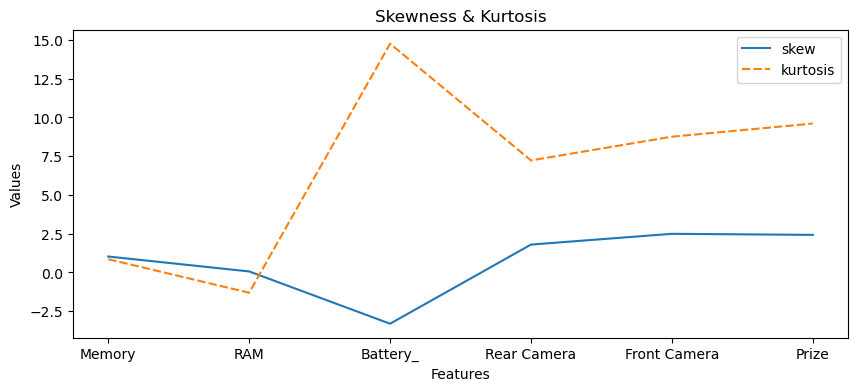

In [55]:
plt.figure(figsize=(10,4))
    
sns.lineplot(data = df1.T)

plt.title('Skewness & Kurtosis')
plt.xlabel('Features')
plt.ylabel('Values')
plt.show()

In [56]:
df1

,Memory,RAM,Battery_,Rear Camera,Front Camera,Prize
skew,1.029704,0.067617,-3.304250,1.799491,2.492864,2.425579
kurtosis,0.855888,-1.306301,14.752188,7.227342,8.756549,9.606035


In [57]:
#To identify the numerical features associated with phone price, correlation analysis is performed. 
#The Unnamed: 0 column is excluded because it represents the dataset's index/row number rather than an actual phone feature

In [58]:
corr = df.drop(columns = ['Unnamed: 0']).select_dtypes(include = 'number').corr()

corr['Prize'].sort_values(ascending = False)

Prize            1.000000
Memory           0.566660
Front Camera     0.532321
RAM              0.532024
Rear Camera      0.410367
Mobile Height    0.176009
Battery_        -0.034297
AI Lens         -0.153691
Name: Prize, dtype: float64

In [59]:
#correlation analysis suggests:
#Memory, Front Camera, RAM and Rear Camera are the strongest numerical features associated with phone price, 
#while Mobile Height has a weak relationship and Battery and AI Lens have little to weak linear relationships with price.

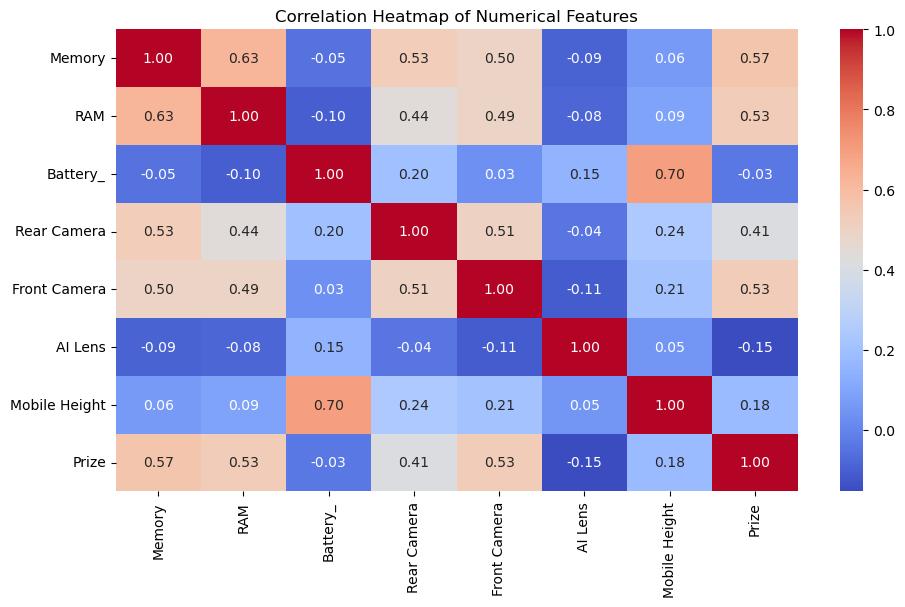

In [60]:
plt.figure(figsize = (11,6))

sns.heatmap(corr, annot = True, fmt='0.2f', cmap='coolwarm')

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

In [61]:
df.dtypes

Unnamed: 0         int64
Model             object
Colour            object
Memory             int64
RAM                int64
Battery_           int64
Rear Camera        int64
Front Camera       int64
AI Lens            int64
Mobile Height    float64
Processor_        object
Prize              int64
dtype: object

In [62]:
df['Model'].value_counts()

Model
vivo Y16                 9
realme C55               9
SAMSUNG Galaxy A14 5G    9
REDMI Note 12 Pro 5G     9
vivo T1 44W              8
                        ..
vivo Y1s                 1
OnePlus Nord             1
Micromax 3               1
vivo Y33s                1
OPPO A77                 1
Name: count, Length: 187, dtype: int64

In [63]:
df['Colour'].value_counts()

Colour
Yellow            12
Royal Blue         8
Power Black        8
Black              8
Midnight Black     7
                  ..
Polar Blue         1
Cosmic grey        1
Sea                1
Infinity Black     1
Sky Blue           1
Name: count, Length: 275, dtype: int64

In [64]:
df['Processor_'].value_counts()

Processor_
Qualcomm Snapdragon 680        33
Unisoc T612                    21
Mediatek Helio A22             19
Mediatek Dimensity 1080        18
Qualcomm Snapdragon 695 5G     17
                               ..
Qualcomm Snapdragon 439         1
Snapdragon 680                  1
snapdragon 888                  1
Qualcomm Snapdragon 855         1
Qualcomm Snapdragon 8 Gen 2     1
Name: count, Length: 123, dtype: int64

In [65]:
#to find unique values

In [66]:
df['Processor_'].sort_values().unique()

array(['0 0 0 208MHz', '2GHz, Quad Core ', '6 Core', 'Android',
       'Dimensity 1080, Octa Core ', 'Dimensity 6020', 'Dimensity 8020',
       'Dimensity 810', 'Dimensity 8100', 'Dimensity 8200',
       'Exynos 1330, Octa Core ', 'Exynos 1380, Octa Core ', 'Exynos 850',
       'Exynos Octa Core', 'G37', 'Google Tensor', 'Google Tensor G2',
       'Helio A22', 'Helio G25', 'Helio G36', 'Helio G85', 'Helio G88',
       'Helio G99', 'IOS', 'MT6260A', 'MTK Dimensity 700', 'MTK6261D',
       'MediaTek', 'MediaTek Dimensity 700', 'MediaTek Dimensity 800U',
       'MediaTek G35', 'MediaTek G37', 'MediaTek Helio A20',
       'MediaTek Helio A22', 'MediaTek Helio G25', 'MediaTek Helio G35',
       'MediaTek Helio G37', 'MediaTek Helio G70', 'MediaTek Helio G80',
       'MediaTek Helio G85', 'MediaTek Helio G88', 'MediaTek Helio G95',
       'MediaTek Helio G96', 'MediaTek Helio P35',
       'Mediatek Dimensity 1080', 'Mediatek Dimensity 1080 5G',
       'Mediatek Dimensity 1300', 'Mediatek Dim

In [67]:
df['Processor_'].value_counts()

Processor_
Qualcomm Snapdragon 680        33
Unisoc T612                    21
Mediatek Helio A22             19
Mediatek Dimensity 1080        18
Qualcomm Snapdragon 695 5G     17
                               ..
Qualcomm Snapdragon 439         1
Snapdragon 680                  1
snapdragon 888                  1
Qualcomm Snapdragon 855         1
Qualcomm Snapdragon 8 Gen 2     1
Name: count, Length: 123, dtype: int64

In [68]:
#about colour to iddentify & understand if the prize matters over colour

In [69]:
df.groupby('Colour')['Prize'].mean().sort_values(ascending=False
                                            )

Colour
Midnight         80999.0
Purple           80999.0
Starlight        80999.0
Cream            79999.0
Lemongrass       55999.0
                  ...   
Cyan              5998.0
SapphireBlack     5990.0
Country Green     5974.0
Light Silver      4943.0
M3)               2417.4
Name: Prize, Length: 275, dtype: float64

## Cleaning the processor column
`Processor_` had 123 different labels for far fewer real chips: extra spaces, upper/lower case, the brand written in different ways (`Mediatek`, `MediaTek`, `Meditek`, `MTK`), part numbers, and entries that were not processors at all (`Android`, `IOS`, `6 Core`, `0 0 0 208MHz`).

It was standardised step by step into `Processor_clean`: strip spaces, then lower case, then merge spelling variants, then look up the real chip by hand for the odd entries. The result is one consistent label per chip.

In [70]:
#Prepocessing

In [71]:
#clean categorical text - not all but example of data set hence first 10

In [72]:
df[['Model','Colour','Processor_']].head(10)

,Model,Colour,Processor_
0,Infinix SMART 7,Night Black,Unisoc Spreadtrum SC9863A1
1,Infinix SMART 7,Azure Blue,Unisoc Spreadtrum SC9863A1
2,MOTOROLA G32,Mineral Gray,Qualcomm Snapdragon 680
3,POCO C50,Royal Blue,Mediatek Helio A22
4,Infinix HOT 30i,Marigold,G37
5,Infinix HOT 30i,Glacier Blue,G37
6,Infinix HOT 30i,Mirror Black,G37
7,Infinix HOT 30i,Diamond White,G37
8,Infinix HOT 30i,Diamond White,G37
9,Infinix HOT 30i,Mirror Black,G37


In [73]:
#figuring out inconsistencies

In [74]:
df[['Model','Processor_','Colour']].map(lambda x: x!=x.strip()).sum()

Model          0
Processor_    18
Colour         0
dtype: int64

In [75]:
#found whitespace in processor = 18
#so further we will check inconsistencies in processor to start with

In [76]:
df['Processor_'].sort_values().unique()

array(['0 0 0 208MHz', '2GHz, Quad Core ', '6 Core', 'Android',
       'Dimensity 1080, Octa Core ', 'Dimensity 6020', 'Dimensity 8020',
       'Dimensity 810', 'Dimensity 8100', 'Dimensity 8200',
       'Exynos 1330, Octa Core ', 'Exynos 1380, Octa Core ', 'Exynos 850',
       'Exynos Octa Core', 'G37', 'Google Tensor', 'Google Tensor G2',
       'Helio A22', 'Helio G25', 'Helio G36', 'Helio G85', 'Helio G88',
       'Helio G99', 'IOS', 'MT6260A', 'MTK Dimensity 700', 'MTK6261D',
       'MediaTek', 'MediaTek Dimensity 700', 'MediaTek Dimensity 800U',
       'MediaTek G35', 'MediaTek G37', 'MediaTek Helio A20',
       'MediaTek Helio A22', 'MediaTek Helio G25', 'MediaTek Helio G35',
       'MediaTek Helio G37', 'MediaTek Helio G70', 'MediaTek Helio G80',
       'MediaTek Helio G85', 'MediaTek Helio G88', 'MediaTek Helio G95',
       'MediaTek Helio G96', 'MediaTek Helio P35',
       'Mediatek Dimensity 1080', 'Mediatek Dimensity 1080 5G',
       'Mediatek Dimensity 1300', 'Mediatek Dim

In [77]:
df['Processor_'].str.lower().nunique()

113

In [78]:
df['Processor_'].nunique()

123

In [79]:
df['Processor_'].str.strip().nunique()

123

In [80]:
#to check extra spaces in between names

In [81]:
df['Processor_'][df['Processor_'].str.contains("  ")].unique()

array([], dtype=object)

In [82]:
#there are no processor names with double spaces inside.

In [83]:
df['Processor_'].str.lower().nunique()

113

In [84]:
#To identify formatting inconsistencies in the Processor_ column, we check for values containing leading or trailing whitespace. 
#This helps ensure that processor names are stored consistently before performing further categorical analysis.

In [85]:
df.loc[df['Processor_'].map(lambda x:x != x.strip()),
    'Processor_']

65        Exynos 1330, Octa Core 
89        Exynos 1330, Octa Core 
90        Exynos 1330, Octa Core 
91        Exynos 1330, Octa Core 
112       Exynos 1330, Octa Core 
115       Exynos 1330, Octa Core 
130       Exynos 1330, Octa Core 
132       Exynos 1330, Octa Core 
353              2GHz, Quad Core 
355              2GHz, Quad Core 
380    Dimensity 1080, Octa Core 
382    Dimensity 1080, Octa Core 
403    Dimensity 1080, Octa Core 
441    Dimensity 1080, Octa Core 
444    Dimensity 1080, Octa Core 
465       Exynos 1380, Octa Core 
515       Exynos 1380, Octa Core 
539       Exynos 1380, Octa Core 
Name: Processor_, dtype: object

In [86]:
#actual cleaning step

In [87]:
df['Processor_']=df['Processor_'].str.strip()

In [88]:
df['Processor_']

0       Unisoc Spreadtrum SC9863A1
1       Unisoc Spreadtrum SC9863A1
2          Qualcomm Snapdragon 680
3               Mediatek Helio A22
4                              G37
                  ...             
536    Qualcomm Snapdragon 8 Gen 2
537                      Octa Core
538             MediaTek Helio G35
539         Exynos 1380, Octa Core
540             Mediatek Helio G35
Name: Processor_, Length: 541, dtype: object

In [89]:
df['Processor_'].map(lambda x:x!=x.strip()).sum()

np.int64(0)

In [90]:
#processor cleaned 

In [91]:
#to the next type of inconsistency: capitalization.

In [92]:
df['Processor_'].str.lower().nunique()

113

In [93]:
df.loc[df['Processor_'].str.lower().duplicated(keep=False), 'Processor_'].sort_values()

355              2GHz, Quad Core
353              2GHz, Quad Core
380    Dimensity 1080, Octa Core
444    Dimensity 1080, Octa Core
403    Dimensity 1080, Octa Core
                 ...            
360            Unisoc Tiger T616
359            Unisoc Tiger T616
474                          ios
532                          ios
525                          ios
Name: Processor_, Length: 511, dtype: object

In [94]:
#To identify inconsistencies caused by differences in capitalization, 
#the unique processor values are compared after temporarily converting them to lowercase. 
#This helps determine whether the same processor has been recorded using different capitalization.

In [95]:
processor_case_check=df['Processor_'].groupby(df['Processor_'].str.lower()).unique()

processor_case_check[processor_case_check.apply(len)>1]

Processor_
ios                                                             [ios, IOS]
mediatek dimensity 700    [Mediatek Dimensity 700, MediaTek Dimensity 700]
mediatek helio a22                [Mediatek Helio A22, MediaTek Helio A22]
mediatek helio g35                [Mediatek Helio G35, MediaTek Helio G35]
mediatek helio g37                [Mediatek Helio G37, MediaTek Helio G37]
mediatek helio g85                [Mediatek Helio G85, MediaTek Helio G85]
mediatek helio g88                [MediaTek Helio G88, Mediatek Helio G88]
mediatek helio g95                [MediaTek Helio G95, Mediatek Helio G95]
mediatek helio g96                [Mediatek Helio G96, MediaTek Helio G96]
mediatek helio p35                [Mediatek Helio P35, MediaTek Helio P35]
Name: Processor_, dtype: object

In [96]:
df['Processor_'].sort_values().unique()

array(['0 0 0 208MHz', '2GHz, Quad Core', '6 Core', 'Android',
       'Dimensity 1080, Octa Core', 'Dimensity 6020', 'Dimensity 8020',
       'Dimensity 810', 'Dimensity 8100', 'Dimensity 8200',
       'Exynos 1330, Octa Core', 'Exynos 1380, Octa Core', 'Exynos 850',
       'Exynos Octa Core', 'G37', 'Google Tensor', 'Google Tensor G2',
       'Helio A22', 'Helio G25', 'Helio G36', 'Helio G85', 'Helio G88',
       'Helio G99', 'IOS', 'MT6260A', 'MTK Dimensity 700', 'MTK6261D',
       'MediaTek', 'MediaTek Dimensity 700', 'MediaTek Dimensity 800U',
       'MediaTek G35', 'MediaTek G37', 'MediaTek Helio A20',
       'MediaTek Helio A22', 'MediaTek Helio G25', 'MediaTek Helio G35',
       'MediaTek Helio G37', 'MediaTek Helio G70', 'MediaTek Helio G80',
       'MediaTek Helio G85', 'MediaTek Helio G88', 'MediaTek Helio G95',
       'MediaTek Helio G96', 'MediaTek Helio P35',
       'Mediatek Dimensity 1080', 'Mediatek Dimensity 1080 5G',
       'Mediatek Dimensity 1300', 'Mediatek Dimensi

In [97]:
df['Processor_'].value_counts()

Processor_
Qualcomm Snapdragon 680        33
Unisoc T612                    21
Mediatek Helio A22             19
Mediatek Dimensity 1080        18
Qualcomm Snapdragon 695 5G     17
                               ..
Qualcomm Snapdragon 439         1
Snapdragon 680                  1
snapdragon 888                  1
Qualcomm Snapdragon 855         1
Qualcomm Snapdragon 8 Gen 2     1
Name: count, Length: 123, dtype: int64

In [98]:
df['Processor_'].str.contains('680', case = False, na = False)

0      False
1      False
2       True
3      False
4      False
       ...  
536    False
537    False
538    False
539    False
540    False
Name: Processor_, Length: 541, dtype: bool

In [99]:
#to locate values where this condition is satisfied

In [100]:
df.loc[df['Processor_'].str.contains('680', case = False),'Processor_'].value_counts()

Processor_
Qualcomm Snapdragon 680                     33
Qualcomm Snapdragon 680 (SM6225)             2
Snapdragon 680                               1
Qualcomm SM6225 Snapdragon 680 4G (6 nm)     1
Name: count, dtype: int64

In [101]:
df.loc[df['Processor_'].str.contains('695', case = False),'Processor_'].value_counts()

Processor_
Qualcomm Snapdragon 695 5G          17
Qualcomm Snapdragon 695              7
Snapdragon 695                       4
Qualcomm Snapdragon 695 (SM6375)     3
Name: count, dtype: int64

In [102]:
#Extract the likely processor family

In [103]:
from collections import Counter

In [104]:
word = ' '.join(df['Processor_'].astype(str)).lower().split()

word

['unisoc',
 'spreadtrum',
 'sc9863a1',
 'unisoc',
 'spreadtrum',
 'sc9863a1',
 'qualcomm',
 'snapdragon',
 '680',
 'mediatek',
 'helio',
 'a22',
 'g37',
 'g37',
 'g37',
 'g37',
 'g37',
 'g37',
 'qualcomm',
 'snapdragon',
 '680',
 'g37',
 'unisoc',
 'spreadtrum',
 'sc9863a1',
 'exynos',
 '850',
 'mediatek',
 'helio',
 'p35',
 'helio',
 'g36',
 'g37',
 'helio',
 'g36',
 'mediatek',
 'helio',
 'a22',
 'unisoc',
 't606',
 'dimensity',
 '6020',
 'dimensity',
 '6020',
 'dimensity',
 '6020',
 'dimensity',
 '6020',
 'dimensity',
 '6020',
 'dimensity',
 '6020',
 'dimensity',
 '6020',
 'dimensity',
 '6020',
 'spreadtrum',
 'sc9863a1',
 'mediatek',
 'helio',
 'a22',
 'mediatek',
 'helio',
 'a22',
 'mediatek',
 'helio',
 'g85',
 'mediatek',
 'helio',
 'a22',
 'mediatek',
 'helio',
 'g85',
 'mediatek',
 'helio',
 'g85',
 'mediatek',
 'helio',
 'g85',
 'exynos',
 '850',
 'exynos',
 '850',
 'helio',
 'g85',
 'mediatek',
 'dimensity',
 '700',
 'mediatek',
 'helio',
 'g37',
 'qualcomm',
 'snapdragon',


In [105]:
word[:30]

['unisoc',
 'spreadtrum',
 'sc9863a1',
 'unisoc',
 'spreadtrum',
 'sc9863a1',
 'qualcomm',
 'snapdragon',
 '680',
 'mediatek',
 'helio',
 'a22',
 'g37',
 'g37',
 'g37',
 'g37',
 'g37',
 'g37',
 'qualcomm',
 'snapdragon',
 '680',
 'g37',
 'unisoc',
 'spreadtrum',
 'sc9863a1',
 'exynos',
 '850',
 'mediatek',
 'helio',
 'p35']

In [106]:
Counter(word).most_common()

[('mediatek', 215),
 ('helio', 152),
 ('snapdragon', 129),
 ('qualcomm', 116),
 ('dimensity', 109),
 ('unisoc', 59),
 ('5g', 39),
 ('680', 37),
 ('695', 31),
 ('core', 28),
 ('t612', 25),
 ('octa', 25),
 ('810', 25),
 ('g37', 24),
 ('1080', 24),
 ('a22', 23),
 ('g99', 21),
 ('p35', 19),
 ('g85', 19),
 ('g35', 19),
 ('exynos', 18),
 ('gen', 17),
 ('g88', 16),
 ('778g', 14),
 ('g96', 12),
 ('sc9863a1', 11),
 ('700', 11),
 ('1', 10),
 ('spreadtrum', 9),
 ('920', 9),
 ('sec', 9),
 ('s5e8535', 9),
 ('(exynos', 9),
 ('1330)', 9),
 ('6020', 8),
 ('1330,', 8),
 ('tensor', 8),
 ('900', 8),
 ('sc6531e', 7),
 ('888', 7),
 ('2', 7),
 ('t616', 7),
 ('850', 6),
 ('750g', 6),
 ('g95', 6),
 ('685', 6),
 ('4', 6),
 ('8100', 6),
 ('7+', 6),
 ('(4nm)', 6),
 ('g2', 6),
 ('t606', 5),
 ('google', 5),
 ('t610', 5),
 ('sc9863a', 5),
 ('1080,', 5),
 ('g25', 5),
 ('meditek', 4),
 ('sc9863a/', 4),
 ('ios', 4),
 ('8020', 3),
 ('0', 3),
 ('processor', 3),
 ('tiger', 3),
 ('8', 3),
 ('7200', 3),
 ('778g+', 3),
 ('(

In [107]:
#Processor Data Standardization:
#The Processor_ feature was examined for inconsistencies in naming conventions. 
#The dataset contains 123 unique processor labels, with variations in capitalization,naming format, abbreviations, and additional technical descriptions.

#To identify recurring processor patterns and determine appropriate processor families, 
#the unique processor labels and their respective frequencies were analyzed.

#This analysis will help standardize equivalent processor names before encoding the categorical feature for machine learning.

In [108]:
processor_list = df['Processor_'].value_counts().reset_index()

processor_list

,Processor_,count
0,Qualcomm Snapdragon 680,33
1,Unisoc T612,21
2,Mediatek Helio A22,19
3,Mediatek Dimensity 1080,18
4,Qualcomm Snapdragon 695 5G,17
...,...,...
118,Qualcomm Snapdragon 439,1
119,Snapdragon 680,1
120,snapdragon 888,1
121,Qualcomm Snapdragon 855,1


In [109]:
df['Processor_'].str.lower().str.split().str[0]

0        unisoc
1        unisoc
2      qualcomm
3      mediatek
4           g37
         ...   
536    qualcomm
537        octa
538    mediatek
539      exynos
540    mediatek
Name: Processor_, Length: 541, dtype: object

In [110]:
# lets count the frequency for these first names

In [111]:
df['Processor_'].str.lower().str.split().str[0].value_counts()

Processor_
mediatek             215
qualcomm             116
unisoc                55
dimensity             28
helio                 27
exynos                18
snapdragon            13
sec                    9
g37                    8
sc6531e                7
spreadtrum             6
google                 5
octa                   5
ios                    4
meditek                4
tensor                 3
octa-core(exynos)      3
sc9863a                3
2ghz,                  2
oxygen                 2
mtk                    1
qualcommâ®             1
octa-core              1
mtk6261d               1
android                1
mt6260a                1
0                      1
6                      1
Name: count, dtype: int64

In [112]:
df.loc[~df['Processor_'].str.lower().str.startswith(
    ('unisoc','mediatek','qualcomm','dimensity','g37','octa','exynos')
),'Processor_'].value_counts()

Processor_
Helio G88                    10
SEC S5E8535 (Exynos 1330)     9
SC6531E                       7
Helio G99                     6
Snapdragon 685                6
Snapdragon 695                4
Helio G25                     4
Meditek Helio G37             4
Spreadtrum SC9863A1           4
Helio G85                     3
ios                           3
Google Tensor G2              3
SC9863A                       3
Tensor G2                     3
2GHz, Quad Core               2
Helio A22                     2
Oxygen OS                     2
Helio G36                     2
Spreadtrum                    2
Google Tensor                 2
Android                       1
MTK6261D                      1
Snapdragon 8 Gen 1            1
MT6260A                       1
0 0 0 208MHz                  1
Snapdragon 680                1
snapdragon 888                1
MTK Dimensity 700             1
IOS                           1
6 Core                        1
Name: count, dtype: int64

In [113]:
processor_list

,Processor_,count
0,Qualcomm Snapdragon 680,33
1,Unisoc T612,21
2,Mediatek Helio A22,19
3,Mediatek Dimensity 1080,18
4,Qualcomm Snapdragon 695 5G,17
...,...,...
118,Qualcomm Snapdragon 439,1
119,Snapdragon 680,1
120,snapdragon 888,1
121,Qualcomm Snapdragon 855,1


In [114]:
processor_list = df['Processor_'].value_counts().reset_index()

In [115]:
processor_list

,Processor_,count
0,Qualcomm Snapdragon 680,33
1,Unisoc T612,21
2,Mediatek Helio A22,19
3,Mediatek Dimensity 1080,18
4,Qualcomm Snapdragon 695 5G,17
...,...,...
118,Qualcomm Snapdragon 439,1
119,Snapdragon 680,1
120,snapdragon 888,1
121,Qualcomm Snapdragon 855,1


In [116]:
df['Processor_clean']=df['Processor_']

In [117]:
#we've copied all contains in processor_clean column to process cleaning on processor_clean before finally performing it onn processor_

In [118]:
df[['Processor_','Processor_clean']].head(10
                                        )

,Processor_,Processor_clean
0,Unisoc Spreadtrum SC9863A1,Unisoc Spreadtrum SC9863A1
1,Unisoc Spreadtrum SC9863A1,Unisoc Spreadtrum SC9863A1
2,Qualcomm Snapdragon 680,Qualcomm Snapdragon 680
3,Mediatek Helio A22,Mediatek Helio A22
4,G37,G37
5,G37,G37
6,G37,G37
7,G37,G37
8,G37,G37
9,G37,G37


In [119]:
df['Processor_clean']=df['Processor_clean'].str.lower()
df['Processor_clean']

0       unisoc spreadtrum sc9863a1
1       unisoc spreadtrum sc9863a1
2          qualcomm snapdragon 680
3               mediatek helio a22
4                              g37
                  ...             
536    qualcomm snapdragon 8 gen 2
537                      octa core
538             mediatek helio g35
539         exynos 1380, octa core
540             mediatek helio g35
Name: Processor_clean, Length: 541, dtype: object

In [120]:
df['Processor_clean'].value_counts()

Processor_clean
qualcomm snapdragon 680        33
mediatek helio a22             21
unisoc t612                    21
mediatek helio p35             19
mediatek dimensity 1080        18
                               ..
qualcomm snapdragon 845         1
qualcomm snapdragon 439         1
snapdragon 680                  1
snapdragon 888                  1
qualcomm snapdragon 8 gen 2     1
Name: count, Length: 113, dtype: int64

In [121]:
df['Processor_clean'].sort_index().value_counts().unique()

array([33, 21, 19, 18, 17, 16, 10,  9,  8,  7,  6,  5,  4,  3,  2,  1])

In [122]:
df['Processor_clean'].sort_index().value_counts()

Processor_clean
qualcomm snapdragon 680        33
mediatek helio a22             21
unisoc t612                    21
mediatek helio p35             19
mediatek dimensity 1080        18
                               ..
qualcomm snapdragon 845         1
qualcomm snapdragon 439         1
snapdragon 680                  1
snapdragon 888                  1
qualcomm snapdragon 8 gen 2     1
Name: count, Length: 113, dtype: int64

In [123]:
df['Processor_clean'].sort_index().unique()

array(['unisoc spreadtrum sc9863a1', 'qualcomm snapdragon 680',
       'mediatek helio a22', 'g37', 'exynos 850', 'mediatek helio p35',
       'helio g36', 'unisoc t606', 'dimensity 6020',
       'spreadtrum sc9863a1', 'mediatek helio g85', 'helio g85',
       'mediatek dimensity 700', 'mediatek helio g37', 'snapdragon 695',
       'qualcomm snapdragon 695 5g', 'mediatek helio g99', 'unisoc t612',
       'exynos 1330, octa core', 'mediatek dimensity 930',
       'qualcomm snapdragon 695', 'mediatek helio g96', 'helio g99',
       'helio g88', 'sc6531e', 'mediatek dimensity 810',
       'mediatek dimensity 800u', 'mediatek dimensity 810 5g',
       'qualcomm snapdragon 750g', 'dimensity 8020', 'mediatek helio g95',
       'mediatek helio g99 octa core', 'mediatek', 'google tensor',
       'dimensity 810', 'qualcomm snapdragon 888', 'snapdragon 685',
       'qualcomm snapdragon 4 gen 1', '0 0 0 208mhz', 'dimensity 8100',
       'unisoc t700', 'mediatek helio g35', 'qualcomm snapdragon 77

In [124]:
# to find how many varients are there for for few varients eg 680,

In [125]:
df.loc[df['Processor_clean'].str.contains('680', case=False, na=False),
    'Processor_clean'
    ].value_counts()

Processor_clean
qualcomm snapdragon 680                     33
qualcomm snapdragon 680 (sm6225)             2
snapdragon 680                               1
qualcomm sm6225 snapdragon 680 4g (6 nm)     1
Name: count, dtype: int64

In [126]:
df.loc[df['Processor_clean'].str.contains('680', case = False, na = False),
    'Processor_clean'
    ] = 'qualcomm snapdragon 680'

In [127]:
df.loc[df['Processor_clean'].str.contains('680',case = False, na = False),
    'Processor_clean'
    ].value_counts()

Processor_clean
qualcomm snapdragon 680    37
Name: count, dtype: int64

In [128]:
# same for 695

In [129]:
df.loc[df['Processor_clean'].str.contains('695', case = False, na = False),
    'Processor_clean'
    ].value_counts()

Processor_clean
qualcomm snapdragon 695 5g          17
qualcomm snapdragon 695              7
snapdragon 695                       4
qualcomm snapdragon 695 (sm6375)     3
Name: count, dtype: int64

In [130]:
#clubbing these

In [131]:
df.loc[df['Processor_clean'].str.contains('695', case = False, na = False),
    'Processor_clean'
    ]= 'qualcomm snapdragon 695'

In [132]:
df.loc[df['Processor_clean'].str.contains('695', case = False, na = False),
    'Processor_clean'
    ].value_counts()

Processor_clean
qualcomm snapdragon 695    31
Name: count, dtype: int64

In [133]:
df['Processor_clean'].value_counts()

Processor_clean
qualcomm snapdragon 680        37
qualcomm snapdragon 695        31
mediatek helio a22             21
unisoc t612                    21
mediatek helio p35             19
                               ..
qualcomm snapdragon 845         1
snapdragon 8 gen 1              1
qualcomm snapdragon 730g        1
android                         1
qualcomm snapdragon 8 gen 2     1
Name: count, Length: 107, dtype: int64

In [134]:
df.loc[df['Processor_clean'].str.contains('G37',case= False, na = False),
    'Processor_clean'
    ].value_counts()

Processor_clean
g37                   8
mediatek helio g37    8
mediatek g37          4
meditek helio g37     4
Name: count, dtype: int64

In [135]:
df.loc[df['Processor_clean'].str.contains('G37', case = False , na = False),
    'Processor_clean'
    ] = 'mediatek helio g37'

In [136]:
df['Processor_clean'].value_counts()

Processor_clean
qualcomm snapdragon 680        37
qualcomm snapdragon 695        31
mediatek helio g37             24
mediatek helio a22             21
unisoc t612                    21
                               ..
snapdragon 8 gen 1              1
qualcomm snapdragon 845         1
qualcomm snapdragon 439         1
snapdragon 888                  1
qualcomm snapdragon 8 gen 2     1
Name: count, Length: 104, dtype: int64

In [137]:
df.loc[df['Processor_clean'].str.contains('8 gen 1', case=False, na=False),
    'Processor_clean',
    ].value_counts()

Processor_clean
qualcomm snapdragon 8 gen 1    1
snapdragon 8 gen 1             1
Name: count, dtype: int64

In [138]:
df.loc[df['Processor_clean'].str.contains('8 gen 1', case = False, na = False),
    'Processor_clean',
    ] = 'qualcomm snapdragon 8 gen 1'

In [139]:
df['Processor_clean'].value_counts()

Processor_clean
qualcomm snapdragon 680        37
qualcomm snapdragon 695        31
mediatek helio g37             24
mediatek helio a22             21
unisoc t612                    21
                               ..
qualcomm snapdragon 439         1
qualcomm snapdragon 845         1
qualcomm snapdragon 730g        1
android                         1
qualcomm snapdragon 8 gen 2     1
Name: count, Length: 103, dtype: int64

In [140]:
df.loc[df['Processor_clean'].str.lower() == 'android']

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean
346,354,OPPO A78 5G,Glowing Black,128,8,5000,13,5,0,16.66,Android,19280,android


In [141]:
df.loc[df['Model'] == 'OPPO A78 5G', 'Processor_clean']='mediatek dimensity 700'

In [142]:
df.loc[df['Processor_clean'].str.lower() == 'android']

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean


In [143]:
df.loc[df['Processor_clean'].str.lower() == 'mediatek dimensity 700']

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean
39,39,POCO M4 5G,Cool Blue,64,4,5000,50,8,0,16.71,Mediatek Dimensity 700,11999,mediatek dimensity 700
58,58,POCO M4 5G,Power Black,64,4,5000,50,8,0,16.71,Mediatek Dimensity 700,11999,mediatek dimensity 700
119,119,POCO M4 5G,Yellow,64,4,5000,50,8,0,16.71,Mediatek Dimensity 700,11999,mediatek dimensity 700
120,120,POCO M4 5G,Yellow,128,6,5000,50,8,0,16.71,Mediatek Dimensity 700,13999,mediatek dimensity 700
171,171,POCO M3 Pro 5G,Yellow,128,6,5000,48,8,0,16.51,MediaTek Dimensity 700,14499,mediatek dimensity 700
289,292,POCO M4 5G,Cool Blue,128,6,5000,50,8,0,16.71,Mediatek Dimensity 700,13999,mediatek dimensity 700
346,354,OPPO A78 5G,Glowing Black,128,8,5000,13,5,0,16.66,Android,19280,mediatek dimensity 700
405,434,vivo Y56 5G,Black Engine,128,8,5000,50,16,0,16.71,Mediatek Dimensity 700,19999,mediatek dimensity 700
428,475,vivo Y56 5G,Orange Shimmer,128,8,5000,50,16,0,16.71,Mediatek Dimensity 700,19999,mediatek dimensity 700
429,476,vivo Y56 5G,Black Engine,128,4,5000,50,16,0,16.71,Mediatek Dimensity 700,17999,mediatek dimensity 700


In [144]:
processors = df['Processor_clean'].unique()
processors[:10]

array(['unisoc spreadtrum sc9863a1', 'qualcomm snapdragon 680',
       'mediatek helio a22', 'mediatek helio g37', 'exynos 850',
       'mediatek helio p35', 'helio g36', 'unisoc t606', 'dimensity 6020',
       'spreadtrum sc9863a1'], dtype=object)

In [145]:
processors[10:100]

array(['mediatek helio g85', 'helio g85', 'mediatek dimensity 700',
       'qualcomm snapdragon 695', 'mediatek helio g99', 'unisoc t612',
       'exynos 1330, octa core', 'mediatek dimensity 930',
       'mediatek helio g96', 'helio g99', 'helio g88', 'sc6531e',
       'mediatek dimensity 810', 'mediatek dimensity 800u',
       'mediatek dimensity 810 5g', 'qualcomm snapdragon 750g',
       'dimensity 8020', 'mediatek helio g95',
       'mediatek helio g99 octa core', 'mediatek', 'google tensor',
       'dimensity 810', 'qualcomm snapdragon 888', 'snapdragon 685',
       'qualcomm snapdragon 4 gen 1', '0 0 0 208mhz', 'dimensity 8100',
       'unisoc t700', 'mediatek helio g35', 'qualcomm snapdragon 778g',
       'unisoc t610', 'unisoc t612 processor', 'mediatek dimensity 1080',
       'mediatek dimensity 920', 'unisoc tiger t612 (12 nm)',
       'qualcomm snapdragon 8 gen 1', 'mediatek dimensity 7200 5g',
       'qualcomm snapdragon 7+ gen 2 (4nm)', 'octa core', 'mt6260a',
       'mtk

In [146]:
processors[100:110]

array(['exynos octa core', 'qualcomm snapdragon 8 gen 2'], dtype=object)

In [147]:
processor_counts = df['Processor_clean'].value_counts(dropna=False)
processor_counts

Processor_clean
qualcomm snapdragon 680              37
qualcomm snapdragon 695              31
mediatek helio g37                   24
mediatek helio a22                   21
unisoc t612                          21
                                     ..
qualcomm snapdragon 888 octa-core     1
qualcomm snapdragon 439               1
qualcomm snapdragon 845               1
qualcomm snapdragon 730g              1
qualcomm snapdragon 8 gen 2           1
Name: count, Length: 102, dtype: int64

In [148]:
print(processor_counts.to_string())
# to see how many values of each type are there

Processor_clean
qualcomm snapdragon 680                        37
qualcomm snapdragon 695                        31
mediatek helio g37                             24
mediatek helio a22                             21
unisoc t612                                    21
mediatek helio p35                             19
mediatek dimensity 1080                        18
mediatek helio g35                             17
mediatek helio g85                             16
mediatek dimensity 700                         11
mediatek helio g99                             10
mediatek dimensity 810                         10
helio g88                                      10
mediatek helio g96                             10
mediatek dimensity 810 5g                      10
sec s5e8535 (exynos 1330)                       9
qualcomm snapdragon 778g                        9
mediatek dimensity 920                          9
mediatek dimensity 900                          8
dimensity 6020                    

In [149]:
processor_counts[processor_counts<2]

Processor_clean
dimensity 8200                         1
6 core                                 1
octa-core                              1
0 0 0 208mhz                           1
qualcomm snapdragon 720g               1
mtk dimensity 700                      1
mediatek helio g25                     1
mediatek dimensity 800u                1
exynos octa core                       1
mediatek helio a20                     1
unisoc tiger t612 (12 nm)              1
unisoc t700                            1
qualcomm snapdragon 855+               1
mediatek helio g80                     1
qualcommâ® snapdragonâ_x0084_¢ 765g    1
mt6260a                                1
qualcomm snapdragon 855                1
snapdragon 888                         1
mtk6261d                               1
mediatek mt6261d                       1
qualcomm snapdragon 888 octa-core      1
qualcomm snapdragon 439                1
qualcomm snapdragon 845                1
qualcomm snapdragon 730g               1


In [150]:
processor_counts[processor_counts.index.str.contains(
    'core|processor|mhz|ios|oxygen|mediatek|unisoc|spreadtrum',
    case = False,
    na = False
)
    ]

Processor_clean
mediatek helio g37                   24
mediatek helio a22                   21
unisoc t612                          21
mediatek helio p35                   19
mediatek dimensity 1080              18
mediatek helio g35                   17
mediatek helio g85                   16
mediatek dimensity 700               11
mediatek helio g99                   10
mediatek dimensity 810               10
mediatek helio g96                   10
mediatek dimensity 810 5g            10
mediatek dimensity 920                9
mediatek dimensity 900                8
exynos 1330, octa core                8
mediatek helio g88                    6
mediatek helio g95                    6
mediatek dimensity 1080 5g            6
unisoc t610                           5
unisoc t616                           5
unisoc t606                           5
dimensity 1080, octa core             5
octa core                             5
ios                                   4
unisoc sc9863a/ unisoc s

In [151]:
df.columns

Index(['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_',
       'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_',
       'Prize', 'Processor_clean'],
      dtype='object')

In [152]:
processor_flags= processor_counts[processor_counts.index.str.contains('core|processor|mhz|ios|oxygen|',case=False, na=False)]
print (processor_flags.to_string())

Processor_clean
qualcomm snapdragon 680                        37
qualcomm snapdragon 695                        31
mediatek helio g37                             24
mediatek helio a22                             21
unisoc t612                                    21
mediatek helio p35                             19
mediatek dimensity 1080                        18
mediatek helio g35                             17
mediatek helio g85                             16
mediatek dimensity 700                         11
mediatek helio g99                             10
mediatek dimensity 810                         10
helio g88                                      10
mediatek helio g96                             10
mediatek dimensity 810 5g                      10
sec s5e8535 (exynos 1330)                       9
qualcomm snapdragon 778g                        9
mediatek dimensity 920                          9
mediatek dimensity 900                          8
dimensity 6020                    

In [153]:
processor_flags

Processor_clean
qualcomm snapdragon 680              37
qualcomm snapdragon 695              31
mediatek helio g37                   24
mediatek helio a22                   21
unisoc t612                          21
                                     ..
qualcomm snapdragon 888 octa-core     1
qualcomm snapdragon 439               1
qualcomm snapdragon 845               1
qualcomm snapdragon 730g              1
qualcomm snapdragon 8 gen 2           1
Name: count, Length: 102, dtype: int64

In [154]:
processor_counts.index.str.contains('core|processor|mhz|ios|oxygen|', case = False, na = False).sum()

np.int64(102)

In [155]:
processor_counts.shape

(102,)

In [156]:
processor_flags= processor_counts[processor_counts.index.str.contains('core|processor|mhz|ios|oxygen|',case=False, na=False)]
print (processor_flags)

Processor_clean
qualcomm snapdragon 680              37
qualcomm snapdragon 695              31
mediatek helio g37                   24
mediatek helio a22                   21
unisoc t612                          21
                                     ..
qualcomm snapdragon 888 octa-core     1
qualcomm snapdragon 439               1
qualcomm snapdragon 845               1
qualcomm snapdragon 730g              1
qualcomm snapdragon 8 gen 2           1
Name: count, Length: 102, dtype: int64


In [157]:
processor_check = (processor_counts.index.str.replace(r'^(qualcomm|mediatek|unisoc|google)\s+','',regex = True)
                  )
processor_check.value_counts().head(30)

Processor_clean
spreadtrum sc9863a1     2
helio g88               2
snapdragon 888          2
helio a22               2
sc9863a                 2
tensor g2               2
helio g85               2
helio g25               2
helio g99               2
dimensity 810           2
tensor                  1
tiger t616              1
snapdragon 680          1
dimensity 930           1
helio g36               1
snapdragon 778g plus    1
snapdragon 888 +        1
snapdragon 8 gen 1      1
oxygen os               1
g99                     1
dimensity 8200          1
spreadtrum              1
snapdragon 8+ gen 1     1
helio g70               1
snapdragon 865          1
g96                     1
g35                     1
2ghz, quad core         1
0 0 0 208mhz            1
6 core                  1
Name: count, dtype: int64

In [158]:
pd.set_option('display.max_rows', None)

In [159]:
#I standardized processor names by identifying inconsistent naming conventions,
#while preserving distinct processor models and variants as separate categories.

In [160]:
df['Processor_clean'].value_counts().sort_index()

Processor_clean
0 0 0 208mhz                                    1
2ghz, quad core                                 2
6 core                                          1
dimensity 1080, octa core                       5
dimensity 6020                                  8
dimensity 8020                                  3
dimensity 810                                   5
dimensity 8100                                  6
dimensity 8200                                  1
exynos 1330, octa core                          8
exynos 1380, octa core                          3
exynos 850                                      6
exynos octa core                                1
google tensor                                   2
google tensor g2                                3
helio a22                                       2
helio g25                                       4
helio g36                                       2
helio g85                                       3
helio g88                         

In [161]:
df[df['Processor_clean'].str.contains('888', case=True, na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean
140,140,realme GT 2,Steel Black,128,8,5000,50,16,0,16.81,Qualcomm Snapdragon 888,23999,qualcomm snapdragon 888
141,141,realme GT 2,Paper White,128,8,5000,50,16,0,16.81,Qualcomm Snapdragon 888,23999,qualcomm snapdragon 888
286,289,SAMSUNG Galaxy Z Flip3 5G,Phantom Black,128,8,3300,12,10,0,17.02,Qualcomm Snapdragon 888 Octa-Core,44999,qualcomm snapdragon 888 octa-core
305,309,MOTOROLA Edge 30 Fusion,Cosmic grey,128,8,4400,50,32,0,16.64,Qualcomm Snapdragon 888 +,34999,qualcomm snapdragon 888 +
419,455,MOTOROLA Edge 30 Fusion,Solar Gold,128,8,4400,50,32,0,16.64,Qualcomm Snapdragon 888 +,34999,qualcomm snapdragon 888 +
445,494,SAMSUNG Galaxy S21 FE 5G,Olive Green,128,8,4500,12,32,0,16.26,snapdragon 888,32999,snapdragon 888
464,530,realme GT 2,Steel Black,256,2,5000,50,16,0,16.81,Qualcomm Snapdragon 888,32299,qualcomm snapdragon 888


In [162]:
df[df['Processor_clean'].str.contains('888 octa-core', case=True, na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean
286,289,SAMSUNG Galaxy Z Flip3 5G,Phantom Black,128,8,3300,12,10,0,17.02,Qualcomm Snapdragon 888 Octa-Core,44999,qualcomm snapdragon 888 octa-core


In [163]:
df['Processor_clean']=df['Processor_clean'].replace({
    'snapdragon 888':'qualcomm snapdragon 888',
    'qualcomm snapdragon 888 octa-core':'qualcomm snapdragon 888'})

In [164]:
df['Processor_clean'].value_counts().sort_index

<bound method Series.sort_index of Processor_clean
qualcomm snapdragon 680                        37
qualcomm snapdragon 695                        31
mediatek helio g37                             24
mediatek helio a22                             21
unisoc t612                                    21
mediatek helio p35                             19
mediatek dimensity 1080                        18
mediatek helio g35                             17
mediatek helio g85                             16
mediatek dimensity 700                         11
helio g88                                      10
mediatek helio g99                             10
mediatek dimensity 810                         10
mediatek helio g96                             10
mediatek dimensity 810 5g                      10
mediatek dimensity 920                          9
sec s5e8535 (exynos 1330)                       9
qualcomm snapdragon 778g                        9
dimensity 6020                                  8

In [165]:
df[df['Processor_clean'].str.contains('810', case = True, na = True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean
101,101,POCO M4 Pro 5G,Yellow,128,8,5000,50,16,0,16.76,Mediatek Dimensity 810,15999,mediatek dimensity 810
109,109,Infinix Note 12 Pro 5G,Force Black,128,8,5000,108,16,0,17.02,Mediatek Dimensity 810 5G,15999,mediatek dimensity 810 5g
110,110,Infinix Note 12 Pro 5G,Snowfall,128,8,5000,108,16,0,17.02,Mediatek Dimensity 810 5G,15999,mediatek dimensity 810 5g
138,138,Infinix HOT 20 5G,Blaster Green,64,4,5000,50,8,1,16.76,Dimensity 810,11499,dimensity 810
144,144,Infinix HOT 20 5G,Space Blue,64,4,5000,50,8,1,16.76,Dimensity 810,11499,dimensity 810
151,151,Infinix HOT 20 5G,Racing Black,64,4,5000,50,8,1,16.76,Dimensity 810,11499,dimensity 810
159,159,REDMI K50i 5G,Stealth Black,256,8,5080,64,16,0,16.76,Dimensity 8100,23999,dimensity 8100
178,178,Infinix Hot 20 5G,Blaster Green,128,6,5000,50,8,1,16.76,Dimensity 810,13499,dimensity 810
186,186,realme 9i 5G,Soulful Blue,128,6,5000,50,8,0,16.76,Mediatek Dimensity 810 5G,16999,mediatek dimensity 810 5g
187,187,realme 9i 5G,Rocking Black,64,4,5000,50,8,0,16.76,Mediatek Dimensity 810 5G,14999,mediatek dimensity 810 5g


In [166]:
df['Processor_clean']=df['Processor_clean'].replace({
    'dimensity 810':'mediatek dimensity 810',
    'mediatek dimensity 810 5g':'mediatek dimensity 810'})

In [167]:
df['Processor_clean'].value_counts().sort_index()

Processor_clean
0 0 0 208mhz                                    1
2ghz, quad core                                 2
6 core                                          1
dimensity 1080, octa core                       5
dimensity 6020                                  8
dimensity 8020                                  3
dimensity 8100                                  6
dimensity 8200                                  1
exynos 1330, octa core                          8
exynos 1380, octa core                          3
exynos 850                                      6
exynos octa core                                1
google tensor                                   2
google tensor g2                                3
helio a22                                       2
helio g25                                       4
helio g36                                       2
helio g85                                       3
helio g88                                      10
helio g99                         

In [168]:
df[df['Processor_clean'].str.contains('1080',case=True,na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean
201,201,REDMI Note 12 Pro 5G,Stardust Purple,256,8,5000,50,16,0,16.94,Mediatek Dimensity 1080,26999,mediatek dimensity 1080
202,202,REDMI Note 12 Pro 5G,Stardust Purple,128,6,5000,50,16,0,16.94,Mediatek Dimensity 1080,23999,mediatek dimensity 1080
209,209,REDMI Note 12 Pro+ 5G,Iceberg Blue,256,8,4980,200,16,0,16.94,Mediatek Dimensity 1080,29999,mediatek dimensity 1080
217,217,REDMI Note 12 Pro+ 5G,Obsidian Black,256,8,4980,200,16,0,16.94,Mediatek Dimensity 1080,29999,mediatek dimensity 1080
220,220,REDMI Note 12 Pro 5G,Glacier Blue,128,6,5000,50,16,0,16.94,Mediatek Dimensity 1080,23999,mediatek dimensity 1080
238,238,REDMI Note 12 Pro 5G,Stardust Purple,128,8,5000,50,16,0,16.94,Mediatek Dimensity 1080,25999,mediatek dimensity 1080
253,253,REDMI Note 12 Pro 5G,Onyx Black,128,8,5000,50,16,0,16.94,Mediatek Dimensity 1080,25999,mediatek dimensity 1080
255,255,REDMI Note 12 Pro+ 5G,Arctic White,256,8,4980,200,16,0,16.94,Mediatek Dimensity 1080,29999,mediatek dimensity 1080
263,264,REDMI Note 12 Pro 5G,Glacier Blue,256,8,5000,50,16,0,16.94,Mediatek Dimensity 1080,26999,mediatek dimensity 1080
264,265,REDMI Note 12 Pro 5G,Onyx Black,128,6,5000,50,16,0,16.94,Mediatek Dimensity 1080,23999,mediatek dimensity 1080


In [169]:
df['Processor_clean']=df['Processor_clean'].replace({
    'mediatek dimensity 1080 5g':'mediatek dimensity 1080',
    'dimensity 1080, octa core':'mediatek dimensity 1080'})

In [170]:
df['Processor_clean'].value_counts().sort_index()

Processor_clean
0 0 0 208mhz                                    1
2ghz, quad core                                 2
6 core                                          1
dimensity 6020                                  8
dimensity 8020                                  3
dimensity 8100                                  6
dimensity 8200                                  1
exynos 1330, octa core                          8
exynos 1380, octa core                          3
exynos 850                                      6
exynos octa core                                1
google tensor                                   2
google tensor g2                                3
helio a22                                       2
helio g25                                       4
helio g36                                       2
helio g85                                       3
helio g88                                      10
helio g99                                       6
ios                               

In [171]:
df[df['Processor_clean'].str.contains('6020',case=True,na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean
20,20,vivo T2x 5G,Aurora Gold,128,8,5000,50,8,0,16.71,Dimensity 6020,15999,dimensity 6020
21,21,vivo T2x 5G,Marine Blue,128,8,5000,50,8,0,16.71,Dimensity 6020,15999,dimensity 6020
22,22,vivo T2x 5G,Glimmer Black,128,8,5000,50,8,0,16.71,Dimensity 6020,15999,dimensity 6020
23,23,vivo T2x 5G,Marine Blue,128,6,5000,50,8,0,16.71,Dimensity 6020,13999,dimensity 6020
24,24,vivo T2x 5G,Glimmer Black,128,4,5000,50,8,0,16.71,Dimensity 6020,12999,dimensity 6020
25,25,vivo T2x 5G,Glimmer Black,128,6,5000,50,8,0,16.71,Dimensity 6020,13999,dimensity 6020
26,26,vivo T2x 5G,Marine Blue,128,4,5000,50,8,0,16.71,Dimensity 6020,12999,dimensity 6020
27,27,vivo T2x 5G,Marine Blue,128,6,5000,50,8,0,16.71,Dimensity 6020,13999,dimensity 6020


In [172]:
df[df['Processor_clean'].str.contains('8020',case=True,na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean
117,117,MOTOROLA Edge 40,Eclipse Black,256,8,4400,50,32,0,16.64,Dimensity 8020,29999,dimensity 8020
154,154,MOTOROLA Edge 40,Nebula Green,256,8,4400,50,32,0,16.64,Dimensity 8020,29999,dimensity 8020
277,280,MOTOROLA Edge 40,Lunar Blue,256,8,4400,50,32,0,16.64,Dimensity 8020,29999,dimensity 8020


In [173]:
df[df['Processor_clean'].str.contains('8100',case=True,na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean
159,159,REDMI K50i 5G,Stealth Black,256,8,5080,64,16,0,16.76,Dimensity 8100,23999,dimensity 8100
306,310,REDMI K50i 5G,Quick Silver,128,6,5080,64,16,0,16.76,Dimensity 8100,21174,dimensity 8100
343,350,REDMI K50i 5G,Stealth Black,128,6,5080,64,16,0,16.76,Dimensity 8100,20998,dimensity 8100
345,353,REDMI K50i 5G,Quick Silver,256,8,5080,64,16,0,16.76,Dimensity 8100,23999,dimensity 8100
369,384,REDMI K50i 5G,Phantom Blue,128,6,5080,64,16,0,16.76,Dimensity 8100,21499,dimensity 8100
518,612,REDMI K50i 5G,Phantom Blue,256,8,5080,64,16,0,16.76,Dimensity 8100,29990,dimensity 8100


In [174]:
df[df['Processor_clean'].str.contains('1330',case=True,na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean
65,65,SAMSUNG Galaxy F14 5G,GOAT Green,128,6,6000,50,13,0,16.76,"Exynos 1330, Octa Core",14490,"exynos 1330, octa core"
89,89,SAMSUNG Galaxy F14 5G,B.A.E. Purple,128,6,6000,50,13,0,16.76,"Exynos 1330, Octa Core",14490,"exynos 1330, octa core"
90,90,SAMSUNG Galaxy F14 5G,B.A.E. Purple,128,4,6000,50,13,0,16.76,"Exynos 1330, Octa Core",13490,"exynos 1330, octa core"
91,91,SAMSUNG Galaxy F14 5G,B.A.E. Purple,128,4,6000,50,13,0,16.76,"Exynos 1330, Octa Core",13490,"exynos 1330, octa core"
112,112,SAMSUNG Galaxy F14 5G,GOAT Green,128,4,6000,50,13,0,16.76,"Exynos 1330, Octa Core",13490,"exynos 1330, octa core"
115,115,SAMSUNG Galaxy F14 5G,OMG Black,128,4,6000,50,13,0,16.76,"Exynos 1330, Octa Core",13490,"exynos 1330, octa core"
130,130,SAMSUNG Galaxy F14 5G,OMG Black,128,6,6000,50,13,0,16.76,"Exynos 1330, Octa Core",14490,"exynos 1330, octa core"
132,132,SAMSUNG Galaxy F14 5G,OMG Black,128,6,6000,50,13,0,16.76,"Exynos 1330, Octa Core",14490,"exynos 1330, octa core"
314,318,SAMSUNG Galaxy A14 5G,Dark Red,64,4,5000,50,13,0,16.76,SEC S5E8535 (Exynos 1330),16499,sec s5e8535 (exynos 1330)
318,322,SAMSUNG Galaxy A14 5G,Black,128,6,5000,50,13,0,16.76,SEC S5E8535 (Exynos 1330),18999,sec s5e8535 (exynos 1330)


In [175]:
df['Processor_clean']=df['Processor_clean'].replace({
    'sec s5e8535 (exynos 1330)':'exynos 1330, octa core'})

In [176]:
df['Processor_clean'].value_counts().sort_index()

Processor_clean
0 0 0 208mhz                                    1
2ghz, quad core                                 2
6 core                                          1
dimensity 6020                                  8
dimensity 8020                                  3
dimensity 8100                                  6
dimensity 8200                                  1
exynos 1330, octa core                         17
exynos 1380, octa core                          3
exynos 850                                      6
exynos octa core                                1
google tensor                                   2
google tensor g2                                3
helio a22                                       2
helio g25                                       4
helio g36                                       2
helio g85                                       3
helio g88                                      10
helio g99                                       6
ios                               

In [177]:
df[df['Processor_clean'].str.contains('tensor',case=True,na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean
135,135,Google Pixel 6a,Chalk,128,6,4410,12,8,0,15.60,Google Tensor,28999,google tensor
136,136,Google Pixel 6a,Charcoal,128,6,4410,12,8,0,15.60,Google Tensor,28999,google tensor
308,312,Google Pixel 7a,Sea,128,8,4300,64,13,0,15.49,Tensor G2,43999,tensor g2
309,313,Google Pixel 7a,Charcoal,128,8,4300,64,13,0,15.49,Tensor G2,43999,tensor g2
327,332,Google Pixel 7a,Snow,128,8,4300,64,13,0,15.49,Tensor G2,43999,tensor g2
416,452,Google Pixel 7,Snow,128,8,4270,50,8,0,16.00,Google Tensor G2,55999,google tensor g2
417,453,Google Pixel 7,Obsidian,128,8,4270,50,8,0,16.00,Google Tensor G2,55999,google tensor g2
426,472,Google Pixel 7,Lemongrass,128,8,4270,50,8,0,16.00,Google Tensor G2,55999,google tensor g2


In [178]:
df['Processor_clean']=df['Processor_clean'].replace({
    'tensor g2':'google tensor g2'})

In [179]:
df['Processor_clean'].value_counts().sort_index()

Processor_clean
0 0 0 208mhz                                    1
2ghz, quad core                                 2
6 core                                          1
dimensity 6020                                  8
dimensity 8020                                  3
dimensity 8100                                  6
dimensity 8200                                  1
exynos 1330, octa core                         17
exynos 1380, octa core                          3
exynos 850                                      6
exynos octa core                                1
google tensor                                   2
google tensor g2                                6
helio a22                                       2
helio g25                                       4
helio g36                                       2
helio g85                                       3
helio g88                                      10
helio g99                                       6
ios                               

In [180]:
df[df['Processor_clean'].str.contains('helio a22',case=True,na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean
3,3,POCO C50,Royal Blue,32,2,5000,8,5,0,16.56,Mediatek Helio A22,5649,mediatek helio a22
18,18,POCO C50,Country Green,32,2,5000,8,5,0,16.56,Mediatek Helio A22,5649,mediatek helio a22
29,29,REDMI A1+,Black,32,3,5000,8,5,0,16.56,Mediatek Helio A22,6599,mediatek helio a22
30,30,REDMI A1+,Light Blue,32,3,5000,8,5,0,16.56,Mediatek Helio A22,6599,mediatek helio a22
32,32,REDMI A1+,Light Green,32,3,5000,8,5,0,16.56,Mediatek Helio A22,6599,mediatek helio a22
53,53,POCO C50,Royal Blue,32,2,5000,8,5,0,16.56,Mediatek Helio A22,6999,mediatek helio a22
73,73,REDMI A1+,Light Blue,32,2,5000,8,5,0,16.56,Mediatek Helio A22,6299,mediatek helio a22
76,76,POCO C50,Royal Blue,32,3,5000,8,5,0,16.56,Mediatek Helio A22,6299,mediatek helio a22
106,106,POCO C50,Country Green,32,3,5000,8,5,0,16.56,Mediatek Helio A22,6299,mediatek helio a22
131,131,REDMI A1+,Light Green,32,2,5000,8,5,0,16.56,Mediatek Helio A22,6299,mediatek helio a22


In [181]:
df['Processor_clean']=df['Processor_clean'].replace({
    'helio a22':'mediatek helio a22'})

In [182]:
df['Processor_clean'].value_counts().sort_index()

Processor_clean
0 0 0 208mhz                                    1
2ghz, quad core                                 2
6 core                                          1
dimensity 6020                                  8
dimensity 8020                                  3
dimensity 8100                                  6
dimensity 8200                                  1
exynos 1330, octa core                         17
exynos 1380, octa core                          3
exynos 850                                      6
exynos octa core                                1
google tensor                                   2
google tensor g2                                6
helio g25                                       4
helio g36                                       2
helio g85                                       3
helio g88                                      10
helio g99                                       6
ios                                             4
mediatek                          

In [183]:
df['Processor_clean']=df['Processor_clean'].replace({
    'helio g25':'mediatek helio g25'})

In [184]:
df['Processor_clean'].value_counts().sort_index()

Processor_clean
0 0 0 208mhz                                    1
2ghz, quad core                                 2
6 core                                          1
dimensity 6020                                  8
dimensity 8020                                  3
dimensity 8100                                  6
dimensity 8200                                  1
exynos 1330, octa core                         17
exynos 1380, octa core                          3
exynos 850                                      6
exynos octa core                                1
google tensor                                   2
google tensor g2                                6
helio g36                                       2
helio g85                                       3
helio g88                                      10
helio g99                                       6
ios                                             4
mediatek                                        3
mediatek dimensity 1080           

In [185]:
replacement_map = {
    'helio g36':'mediatek helio g36',
    'helio g85':'mediatek helio g85',
    'helio g99':'mediatek helio g99',
    'mediatek helio g99 octa core':'mediatek helio g99',
}
    
df['Processor_clean']=df['Processor_clean'].replace(replacement_map)

In [186]:
df['Processor_clean'].value_counts().sort_index()

Processor_clean
0 0 0 208mhz                                    1
2ghz, quad core                                 2
6 core                                          1
dimensity 6020                                  8
dimensity 8020                                  3
dimensity 8100                                  6
dimensity 8200                                  1
exynos 1330, octa core                         17
exynos 1380, octa core                          3
exynos 850                                      6
exynos octa core                                1
google tensor                                   2
google tensor g2                                6
helio g88                                      10
ios                                             4
mediatek                                        3
mediatek dimensity 1080                        29
mediatek dimensity 1300                         3
mediatek dimensity 700                         11
mediatek dimensity 7200 5g        

In [187]:
replacement_map1 = {
    'qualcomm snapdragon 778g 5g mobile platform':'qualcomm snapdragon 778g',
    'qualcomm snapdragon 778g+':'qualcomm snapdragon 778g plus'}

df['Processor_clean']=df['Processor_clean'].replace(replacement_map1)

In [188]:
df['Processor_clean'].value_counts().sort_index()

Processor_clean
0 0 0 208mhz                            1
2ghz, quad core                         2
6 core                                  1
dimensity 6020                          8
dimensity 8020                          3
dimensity 8100                          6
dimensity 8200                          1
exynos 1330, octa core                 17
exynos 1380, octa core                  3
exynos 850                              6
exynos octa core                        1
google tensor                           2
google tensor g2                        6
helio g88                              10
ios                                     4
mediatek                                3
mediatek dimensity 1080                29
mediatek dimensity 1300                 3
mediatek dimensity 700                 11
mediatek dimensity 7200 5g              3
mediatek dimensity 800u                 1
mediatek dimensity 810                 25
mediatek dimensity 900                  8
mediatek dimensity

In [189]:
replacement_map3 = {
    'sc9863a':'unisoc spreadtrum sc9863a1',
    'unisoc sc9863a/ unisoc sc9863a1':'unisoc spreadtrum sc9863a1',
    'spreadtrum sc9863a1':'unisoc spreadtrum sc9863a1',
    'unisoc sc9863a':'unisoc spreadtrum sc9863a1',
}

df['Processor_clean']=df['Processor_clean'].replace(replacement_map3)

In [190]:
replacement_map4 = {
    'unisoc t612 processor':'unisoc t612',
    'unisoc tiger t612 (12 nm)':'unisoc t612',
    'unisoc_t612':'unisoc t612'
    }
df['Processor_clean']=df['Processor_clean'].replace(replacement_map4)

In [191]:
replacement_map5 = {
    'unisoc tiger t616':'unisoc t616',
    'unisoc_t616':'unisoc t616',
    'unisoc_t616':'unisoc t616'
}
df['Processor_clean']=df['Processor_clean'].replace(replacement_map5)

In [192]:
df['Processor_clean'].value_counts().sort_index()

Processor_clean
0 0 0 208mhz                            1
2ghz, quad core                         2
6 core                                  1
dimensity 6020                          8
dimensity 8020                          3
dimensity 8100                          6
dimensity 8200                          1
exynos 1330, octa core                 17
exynos 1380, octa core                  3
exynos 850                              6
exynos octa core                        1
google tensor                           2
google tensor g2                        6
helio g88                              10
ios                                     4
mediatek                                3
mediatek dimensity 1080                29
mediatek dimensity 1300                 3
mediatek dimensity 700                 11
mediatek dimensity 7200 5g              3
mediatek dimensity 800u                 1
mediatek dimensity 810                 25
mediatek dimensity 900                  8
mediatek dimensity

In [193]:
df['Processor_clean']=df['Processor_clean'].replace({
    '0 0 0 208mhz':'mediatek helio g95',
    '2ghz, quad core':'mediatek helio a22',
    '6 core':'Apple A15 Bionic',
    'exynos octa core':'Samsung Exynos 850',
    'exynos 850':'Samsung Exynos 850',
})

In [194]:
#need to find complete rows for these
#0 0 0 208mhz                            1
#2ghz, quad core                         2
#6 core                                  1
#exynos octa core
#ios                                     4
#mediatek 
#mediatek mt6261d                        1
#mt6260a                                 1
#mtk dimensity 700                       1
#mtk6261d                                1
#octa core                               5
#octa-core                               1
#octa-core(exynos)                       3
#oxygen os                               
#spreadtrum
#unisoc
#unisoc_t61

In [195]:
df[df['Processor_clean'].str.contains('mhz',case=True,na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean


In [196]:
df[df['Processor_clean'].str.contains('2ghz',case=True,na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean


In [197]:
df[df['Processor_clean'].str.contains('6 core',case=True,na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean


In [198]:
df[df['Processor_clean'].str.contains('exynos octa core',case=True,na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean


In [199]:
df[df['Processor_clean'].str.contains('ios',case=True,na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean
474,546,APPLE iPhone 11,Black,64,8,3110,12,12,0,15.49,ios,41199,ios
493,576,APPLE iPhone 14 Plus,Midnight,128,6,4323,12,12,0,17.02,IOS,80999,ios
525,621,APPLE iPhone 14 Plus,Starlight,128,4,4323,12,12,0,17.02,ios,80999,ios
532,631,APPLE iPhone 12,Blue,64,8,2815,12,12,0,15.49,ios,53999,ios


In [200]:
df.loc[[474,493,525,532],'Processor_clean']=[
    'Apple A13 Bionic',
    'Apple A15 Bionic',
    'Apple A15 Bionic',
    'Apple A14 Bionic']

In [201]:
df['Processor_clean'].value_counts().sort_index

<bound method Series.sort_index of Processor_clean
qualcomm snapdragon 680                37
qualcomm snapdragon 695                31
mediatek dimensity 1080                29
unisoc t612                            25
mediatek helio a22                     25
mediatek dimensity 810                 25
mediatek helio g37                     24
mediatek helio p35                     19
mediatek helio g85                     19
mediatek helio g99                     19
mediatek helio g35                     17
exynos 1330, octa core                 17
unisoc spreadtrum sc9863a1             16
qualcomm snapdragon 778g               12
mediatek dimensity 700                 11
helio g88                              10
mediatek helio g96                     10
mediatek dimensity 920                  9
dimensity 6020                          8
mediatek dimensity 900                  8
sc6531e                                 7
unisoc t616                             7
Samsung Exynos 850       

In [202]:
#mediatek 
#mediatek mt6261d                        1
#mt6260a                                 1
#mtk dimensity 700                       1
#mtk6261d                                1
#octa core                               5
#octa-core                               1
#octa-core(exynos)                       3
#oxygen os                               
#spreadtrum
#unisoc
#unisoc_t61

In [203]:
df[df['Processor_clean'].str.contains('mediatek',case=True,na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean
3,3,POCO C50,Royal Blue,32,2,5000,8,5,0,16.56,Mediatek Helio A22,5649,mediatek helio a22
4,4,Infinix HOT 30i,Marigold,128,8,5000,50,5,1,16.76,G37,8999,mediatek helio g37
5,5,Infinix HOT 30i,Glacier Blue,128,8,5000,50,5,1,16.76,G37,8999,mediatek helio g37
6,6,Infinix HOT 30i,Mirror Black,128,8,5000,50,5,1,16.76,G37,8999,mediatek helio g37
7,7,Infinix HOT 30i,Diamond White,128,8,5000,50,5,1,16.76,G37,8999,mediatek helio g37
8,8,Infinix HOT 30i,Diamond White,64,4,5000,50,5,1,16.76,G37,7999,mediatek helio g37
9,9,Infinix HOT 30i,Mirror Black,64,4,5000,50,5,1,16.76,G37,7999,mediatek helio g37
11,11,Infinix HOT 30i,Glacier Blue,64,4,5000,50,5,1,16.76,G37,7999,mediatek helio g37
14,14,SAMSUNG Galaxy F04,Opal Green,64,4,5000,13,5,0,16.51,Mediatek Helio P35,7299,mediatek helio p35
15,15,POCO C51,Royal Blue,64,4,5000,8,5,0,16.56,Helio G36,6999,mediatek helio g36


In [204]:
#133,156,193,

In [205]:
# CHECK: 'mediatek g99' is mapped to 'mediatek helio g96' below. Confirm this is intended (should it be g99?)
df['Processor_clean']=df['Processor_clean'].replace({
    'mediatek g35':'mediatek helio g35',
    'mediatek g96':'mediatek helio g96',
    'mediatek g99':'mediatek helio g96',
    'mtk6261d':'mediatek mt6261d',
    'mtk dimensity 700':'mediatek dimensity 700'
})

In [206]:
df.loc[[133,156,193],'Processor_clean']=[
    'mediatek mt6261d',
    'mediatek mt6261d',
    'mediatek mt6261d'
]

In [207]:
df['Processor_clean'].value_counts().sort_index()

Processor_clean
Apple A13 Bionic                        1
Apple A14 Bionic                        1
Apple A15 Bionic                        3
Samsung Exynos 850                      7
dimensity 6020                          8
dimensity 8020                          3
dimensity 8100                          6
dimensity 8200                          1
exynos 1330, octa core                 17
exynos 1380, octa core                  3
google tensor                           2
google tensor g2                        6
helio g88                              10
mediatek dimensity 1080                29
mediatek dimensity 1300                 3
mediatek dimensity 700                 12
mediatek dimensity 7200 5g              3
mediatek dimensity 800u                 1
mediatek dimensity 810                 25
mediatek dimensity 900                  8
mediatek dimensity 920                  9
mediatek dimensity 930                  2
mediatek helio a20                      1
mediatek helio a22

In [208]:
df[df['Processor_clean'].str.contains('mt6260a',case = True, na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean
244,244,redmi max,M3),16,8,1200,2,0,0,6.1,MT6260A,3549,mt6260a


In [209]:
df['Processor_clean']=df['Processor_clean'].replace({
    'MT6260A':'mediatek mt6260a'})

In [210]:
df[df['Processor_clean'].str.contains('spreadtrum',case=True,na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean
0,0,Infinix SMART 7,Night Black,64,4,6000,13,5,1,16.76,Unisoc Spreadtrum SC9863A1,7299,unisoc spreadtrum sc9863a1
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13,5,1,16.76,Unisoc Spreadtrum SC9863A1,7299,unisoc spreadtrum sc9863a1
12,12,Infinix SMART 7,Emerald Green,64,4,6000,13,5,1,16.76,Unisoc Spreadtrum SC9863A1,7299,unisoc spreadtrum sc9863a1
28,28,Infinix Smart 7 HD,Green Apple,64,2,5000,8,5,1,16.76,Spreadtrum SC9863A1,6199,unisoc spreadtrum sc9863a1
122,122,Infinix Smart 7 HD,Ink Black,64,2,5000,8,5,1,16.76,Spreadtrum SC9863A1,6199,unisoc spreadtrum sc9863a1
123,123,Infinix Smart 7 HD,Silk Blue,64,2,5000,8,5,1,16.76,Spreadtrum SC9863A1,6199,unisoc spreadtrum sc9863a1
124,124,Infinix Smart 7 HD,Jade White,64,2,5000,8,5,1,16.76,Spreadtrum SC9863A1,6199,unisoc spreadtrum sc9863a1
246,246,redmi min,M3),16,4,1000,0,0,0,4.57,Spreadtrum,920,spreadtrum
247,247,redmi min,M3),16,4,1000,0,0,0,4.57,Spreadtrum,920,spreadtrum
281,284,realme Narzo 50i,Carbon Black,32,2,5000,8,5,0,16.51,SC9863A,6978,unisoc spreadtrum sc9863a1


In [211]:
#243 - Qualcomm Snapdragon 662,335,343, 633 - unisoc t606  638 - ,641 - octa core

In [212]:
#473 - Qualcomm Snapdragon 680,566 - Qualcomm Snapdragon 680,610 - Unisoc SC9863A,624 - Qualcomm Snapdragon 680/ - octa-core, octa-core(exynos)

In [213]:
#Unisoc Spreadtrum SC6531E, 246, 247 Spreadtrum - redmi min - redmi 6 - MediaTek Helio P22, 376, 382, 383 -  Unisoc SC9832E

In [214]:
df.loc[[243,534,537,427,486,516,528,246,247,362,367,368],'Processor_clean']=[
    'Qualcomm Snapdragon 662',
    'Unisoc T606',
    'Unisoc SC9863',
    'Qualcomm Snapdragon 680',
    'Qualcomm Snapdragon 680',
    'Unisoc SC9863A',
    'Qualcomm Snapdragon 680',
    'Unisoc Spreadtrum SC6531E',
    'Unisoc Spreadtrum SC6531E',
    'Unisoc SC9832E',
    'Unisoc SC9832E',
    'Unisoc SC9832E',
]

In [215]:
df['Processor_clean'].value_counts().sort_index()

Processor_clean
Apple A13 Bionic                        1
Apple A14 Bionic                        1
Apple A15 Bionic                        3
Qualcomm Snapdragon 662                 1
Qualcomm Snapdragon 680                 3
Samsung Exynos 850                      7
Unisoc SC9832E                          3
Unisoc SC9863                           1
Unisoc SC9863A                          1
Unisoc Spreadtrum SC6531E               2
Unisoc T606                             1
dimensity 6020                          8
dimensity 8020                          3
dimensity 8100                          6
dimensity 8200                          1
exynos 1330, octa core                 17
exynos 1380, octa core                  3
google tensor                           2
google tensor g2                        6
helio g88                              10
mediatek dimensity 1080                29
mediatek dimensity 1300                 3
mediatek dimensity 700                 12
mediatek dimensity

In [216]:
#sc6531e,qualcommâ® snapdragonâ_x0084_¢ 765g,oxygen os,mt6260a,helio g88,Unisoc T606,unisoc t606,Unisoc Spreadtrum SC6531E,

In [217]:
df['Model']=df['Model'].replace({
    'OnePlus Nord 2T 5G':'OnePlus Nord 2T',
    
})

In [218]:
df[df['Processor_clean'].str.contains('mediatek octa core 1.6 ghz',case=True,na=True)]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize,Processor_clean


In [219]:
df['Processor_clean']=df['Processor_clean'].replace({
    'sc6531e':'Unisoc Spreadtrum SC6531E',
    'Unisoc SC9863':'Unisoc SC9863A',
    'unisoc t606':'Unisoc T606',
    'helio g88':'mediatek helio g88',
    'qualcommâ® snapdragonâ_x0084_¢ 765g':'Qualcomm Snapdragon 765g',
    'unisoc spreadtrum sc9863a1':'Unisoc SC9863A',
    'snapdragon 685':'qualcomm snapdragon 685',
    'dimensity 6020':'mediatek dimensity 6020',
    'dimensity 8020':'mediatek dimensity 8020',
    'dimensity 8100':'mediatek dimensity 8100',
    'dimensity 8200':'mediatek dimensity 8200',
    'Qualcomm Snapdragon 680':'qualcomm snapdragon 680',
    'mt6260a':'mediatek mt6260a',
    'oxy os':'mediatek dimensity 1300',
    'exynos 1330, octa core':'exynos 1330',
    'exynos 1380, octa core':'exynos 1380',
    'oxygen os':'mediatek dimensity 1300',
    'qualcomm snapdragon 7+ gen 2 (4nm)':'qualcomm snapdragon 7+ gen 2',
    'qualcomm snapdragon 888 +':'qualcomm snapdragon 888+',
    'exynos 1330':'samsung exynos 1330',
    'exynos 1380':'samsung exynos 1380',
    'mediatek dimensity 7200 5g':'mediatek dimensity 7200'
})

In [220]:
df.loc[[330,338],'Processor_clean']='Unisoc T107'


In [221]:
df['Processor_clean'].value_counts().sort_index()

Processor_clean
Apple A13 Bionic                  1
Apple A14 Bionic                  1
Apple A15 Bionic                  3
Qualcomm Snapdragon 662           1
Qualcomm Snapdragon 765g          1
Samsung Exynos 850                7
Unisoc SC9832E                    3
Unisoc SC9863A                   18
Unisoc Spreadtrum SC6531E         9
Unisoc T107                       2
Unisoc T606                       6
exynos 1330                      17
exynos 1380                       3
google tensor                     2
google tensor g2                  6
mediatek dimensity 1080          29
mediatek dimensity 1300           5
mediatek dimensity 6020           8
mediatek dimensity 700           12
mediatek dimensity 7200           3
mediatek dimensity 800u           1
mediatek dimensity 8020           3
mediatek dimensity 810           25
mediatek dimensity 8100           6
mediatek dimensity 8200           1
mediatek dimensity 900            8
mediatek dimensity 920            9
mediatek dim

In [222]:
df['Processor_clean']=df['Processor_clean'].str.lower()

In [223]:
df['Processor_clean'].value_counts().sort_index()

Processor_clean
apple a13 bionic                  1
apple a14 bionic                  1
apple a15 bionic                  3
exynos 1330                      17
exynos 1380                       3
google tensor                     2
google tensor g2                  6
mediatek dimensity 1080          29
mediatek dimensity 1300           5
mediatek dimensity 6020           8
mediatek dimensity 700           12
mediatek dimensity 7200           3
mediatek dimensity 800u           1
mediatek dimensity 8020           3
mediatek dimensity 810           25
mediatek dimensity 8100           6
mediatek dimensity 8200           1
mediatek dimensity 900            8
mediatek dimensity 920            9
mediatek dimensity 930            2
mediatek helio a20                1
mediatek helio a22               25
mediatek helio g25                5
mediatek helio g35               19
mediatek helio g36                2
mediatek helio g37               24
mediatek helio g70                2
mediatek hel

## Manufacturer and Tier
`Manufacturer` is read from the processor name (Qualcomm, Mediatek, Samsung, Unisoc, Google, Apple). `Tier` groups processors by class: Flagship, Mid, low, other.

Both are built **only from the processor, never from the price**, so there is no target leakage.

Limits to remember: the rules are hand-written, and `other` is a catch-all (about 30% of phones). The Tier rule now matches whole chip numbers, because the earlier `'dimensity 810' in x` also matched `dimensity 8100`, a stronger chip, and put it in Mid by accident.

In [224]:
df['Manufacturer']=df['Processor_clean'].apply(
    lambda x: 'Apple' if 'apple' in x else
    'Qualcomm' if 'snapdragon' in x else
    'Mediatek' if 'helio' in x or 'dimensity' in x or 'mt' in x else
    'Samsung' if 'exynos' in x else
    'Unisoc' if 'unisoc' in x or 'sc' in x or 'spreadtrum' in x else
    'Google' if 'tensor' in x else
    'Other'
)

In [225]:
df['Manufacturer'].sort_index()

0        Unisoc
1        Unisoc
2      Qualcomm
3      Mediatek
4      Mediatek
5      Mediatek
6      Mediatek
7      Mediatek
8      Mediatek
9      Mediatek
10     Qualcomm
11     Mediatek
12       Unisoc
13      Samsung
14     Mediatek
15     Mediatek
16     Mediatek
17     Mediatek
18     Mediatek
19       Unisoc
20     Mediatek
21     Mediatek
22     Mediatek
23     Mediatek
24     Mediatek
25     Mediatek
26     Mediatek
27     Mediatek
28       Unisoc
29     Mediatek
30     Mediatek
31     Mediatek
32     Mediatek
33     Mediatek
34     Mediatek
35     Mediatek
36      Samsung
37      Samsung
38     Mediatek
39     Mediatek
40     Mediatek
41     Qualcomm
42     Mediatek
43     Qualcomm
44     Qualcomm
45      Samsung
46     Mediatek
47     Mediatek
48     Mediatek
49     Mediatek
50     Qualcomm
51     Qualcomm
52     Qualcomm
53     Mediatek
54     Qualcomm
55     Qualcomm
56     Mediatek
57     Qualcomm
58     Mediatek
59      Samsung
60      Samsung
61     Mediatek
62      

In [226]:
# This shows you what % of phones are Apple, Qualcomm, MediaTek, Samsung, Unisoc, Google, etc.
# This shows the holdings of each brand.

In [227]:
df['Manufacturer'].value_counts(normalize=True)*100

Manufacturer
Mediatek    53.789279
Qualcomm    24.768946
Unisoc      14.048059
Samsung      4.990758
Google       1.478743
Apple        0.924214
Name: proportion, dtype: float64

In [228]:
# Tier is built from the processor name only (never from price). Whole-number matching, see the note above.
import re

def tier_of(x):
    # \b means a whole-number match, so '810' does not match '8100'
    if re.search(r'8 gen|\b888\b|\b865\b|\ba13\b|\ba14\b|\ba15\b', x):
        return 'Flagship'
    if re.search(r'\b680\b|\b695\b|\bg99\b|dimensity 700\b|dimensity 810\b', x):
        return 'Mid'
    if re.search(r'helio|\b439\b|unisoc', x):
        return 'low'
    return 'other'

df['Tier'] = df['Processor_clean'].apply(tier_of)

In [229]:
df['Tier'].value_counts()

Tier
low         231
other       160
Mid         133
Flagship     17
Name: count, dtype: int64

In [230]:
df['Tier'].sort_index()

0           low
1           low
2           Mid
3           low
4           low
5           low
6           low
7           low
8           low
9           low
10          Mid
11          low
12          low
13        other
14          low
15          low
16          low
17          low
18          low
19          low
20        other
21        other
22        other
23        other
24        other
25        other
26        other
27        other
28          low
29          low
30          low
31          low
32          low
33          low
34          low
35          low
36        other
37        other
38          low
39          Mid
40          low
41          Mid
42          low
43          Mid
44          Mid
45        other
46          low
47          low
48          low
49          low
50          Mid
51          Mid
52          Mid
53          low
54          Mid
55          Mid
56          Mid
57          Mid
58          Mid
59        other
60        other
61          Mid
62      

In [231]:
df['Tier'].value_counts(normalize=True)*100

Tier
low         42.698706
other       29.574861
Mid         24.584104
Flagship     3.142329
Name: proportion, dtype: float64

In [232]:
#to analyze the relationship between these new categorical features and Prize

In [233]:
df.groupby('Tier')['Prize'].mean()

Tier
Flagship    46798.882353
Mid         16146.879699
low          9242.787879
other       23133.443750
Name: Prize, dtype: float64

In [234]:
df.groupby('Manufacturer')['Prize'].mean().sort_values()

Manufacturer
Unisoc       7394.868421
Mediatek    14721.790378
Samsung     17781.518519
Qualcomm    20576.208955
Google      44749.000000
Apple       67639.000000
Name: Prize, dtype: float64

In [235]:
df.groupby('Manufacturer')['Prize'].agg(['count','mean']).sort_values('mean')

,count,mean
Manufacturer,,
Unisoc,76,7394.868421
Mediatek,291,14721.790378
Samsung,27,17781.518519
Qualcomm,134,20576.208955
Google,8,44749.000000
Apple,5,67639.000000


In [236]:
#Mediatek dominates your dataset, with 291 of 541 phones, so about 54% of the dataset.
#Qualcomm is next, with 134 phones.
#The average Prize varies substantially between manufacturers, 
#so Manufacturer looks like a potentially useful feature for explaining phone prices.
#Apple has only 5 phones and Google only 8. Their averages are therefore based on small samples

In [237]:
#we now have the devices & portion of the data that each brand holds

In [238]:
df.columns

Index(['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_',
       'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_',
       'Prize', 'Processor_clean', 'Manufacturer', 'Tier'],
      dtype='object')

In [239]:
df.groupby('Manufacturer')['Model'].value_counts()

Manufacturer  Model                             
Apple         APPLE iPhone 14 Plus                  3
              APPLE iPhone 11                       1
              APPLE iPhone 12                       1
Google        Google Pixel 7                        3
              Google Pixel 7a                       3
              Google Pixel 6a                       2
Mediatek      REDMI Note 12 Pro 5G                  9
              realme C55                            9
              vivo Y16                              9
              Infinix HOT 30i                       8
              vivo T2x 5G                           8
              POCO M5                               6
              REDMI 11 Prime                        6
              REDMI A1+                             6
              REDMI K50i 5G                         6
              REDMI Note 12 Pro+ 5G                 6
              realme 10 Pro+ 5G                     6
              realme 9i 5G       

In [240]:
#number of devices manufacturer holds in market

In [241]:
df.groupby('Manufacturer')['Model'].count()

Manufacturer
Apple         5
Google        8
Mediatek    291
Qualcomm    134
Samsung      27
Unisoc       76
Name: Model, dtype: int64

In [242]:
#% manufacturer % holds in market

In [243]:
df['Manufacturer'].sort_values().value_counts(normalize=True)*100

Manufacturer
Mediatek    53.789279
Qualcomm    24.768946
Unisoc      14.048059
Samsung      4.990758
Google       1.478743
Apple        0.924214
Name: proportion, dtype: float64

In [244]:
#average price each manufacturer holds in market

In [245]:
df.groupby('Manufacturer')['Prize'].mean().sort_values()

Manufacturer
Unisoc       7394.868421
Mediatek    14721.790378
Samsung     17781.518519
Qualcomm    20576.208955
Google      44749.000000
Apple       67639.000000
Name: Prize, dtype: float64

In [246]:
#Manufacturer - No. of devices - Price - % holdings
#Mediatek - 291 - 14721.790378 - 53.789279
#Qualcomm - 134 - 20576.208955 - 24.768946
#Unisoc - 76 - 7394.868421 - 14.048059
#Samsung - 27 - 17781.518519 - 4.990758
#Google - 8 - 44749.000000 - 1.478743
#Apple - 5 - 67639.000000 - 0.924214

In [247]:
###bivariate analysis

In [248]:
#the scatter plot we’re making is all about understanding the relationship between two variables:

#X‑axis → Device Count (how many models each manufacturer has)

#Y‑axis → Average Price (the price level of that manufacturer’s devices)

In [249]:
#Use: Scatter plot
#Purpose: See correlation between two metrics

In [250]:
# Step 1: Create summary table
brand_stats = df.groupby('Manufacturer').agg({
    'Model':'count',
    'Prize':'mean'
})

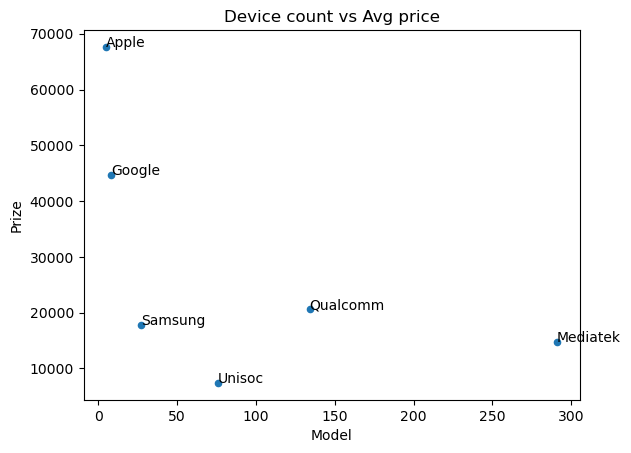

In [251]:
ax=brand_stats.plot.scatter(x='Model',y='Prize',title = 'Device count vs Avg price')
for i, txt in enumerate(brand_stats.index):
    ax.annotate(txt,(brand_stats['Model'].iloc[i],brand_stats['Prize'].iloc[i]))

<Axes: title={'center': 'Average price per manufacturer'}, xlabel='Manufacturer'>

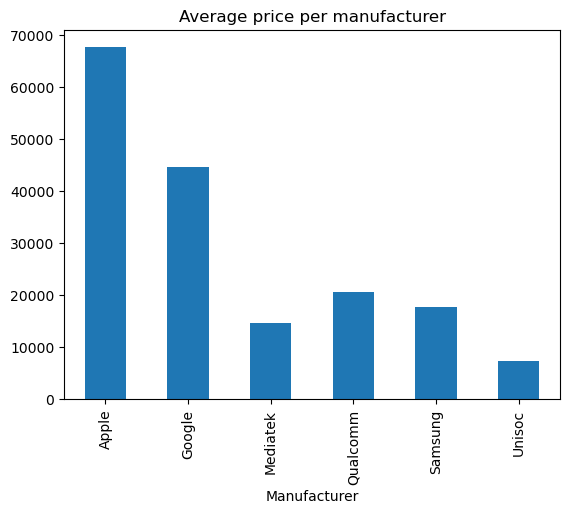

In [252]:
brand_stats['Prize'].plot(kind='bar', title='Average price per manufacturer')

<Axes: xlabel='Prize', ylabel='Count'>

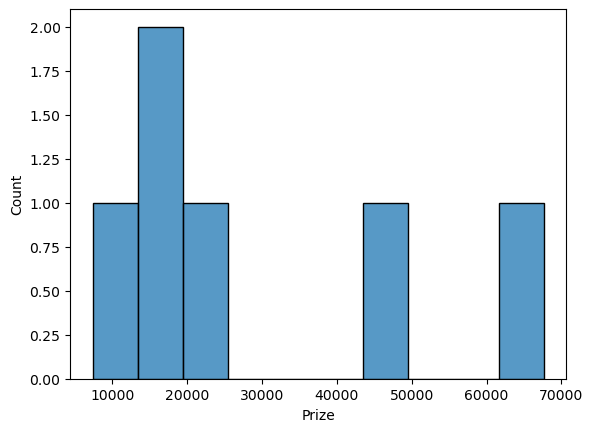

In [253]:
sns.histplot(data=brand_stats,x = 'Prize', bins = 10)

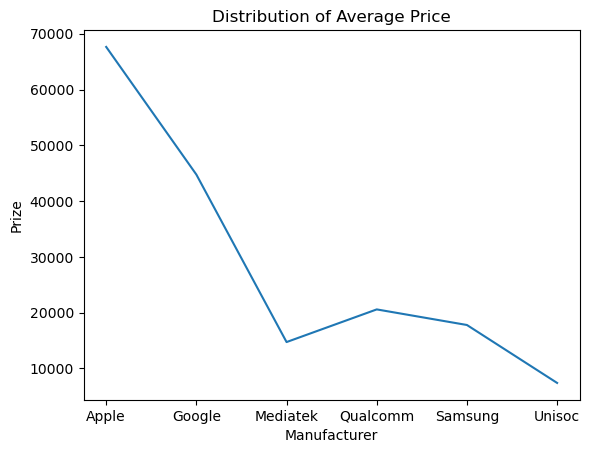

In [254]:
sns.lineplot(data=brand_stats,x = 'Manufacturer', y='Prize')
plt.title('Distribution of Average Price')
plt.xlabel('Manufacturer')
plt.ylabel('Prize')
plt.show()

In [255]:
#This plot shows the average price associated with each manufacturer. 
#Apple stands out with the highest average price, followed by Google.
#Qualcomm and Samsung are mid‑range, while Mediatek and Unisoc offer lower‑priced devices. 
#The line visually connects these categories, but the key takeaway is the stark difference in pricing strategies across brands.

In [256]:
#Apple → premium pricing, far above others.

#Google → second highest, but still much lower than Apple.

#Qualcomm & Samsung → moderate pricing range.

#Mediatek & Unisoc → budget‑friendly, lowest averages.

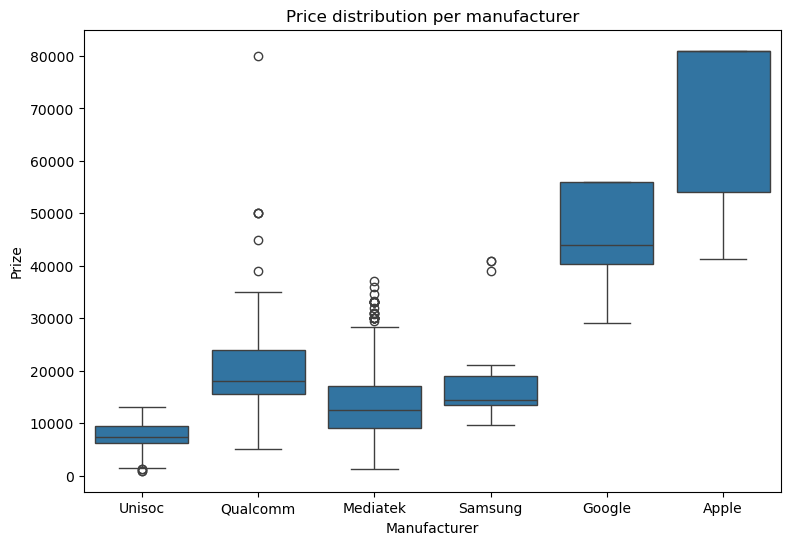

In [257]:
plt.figure(figsize=(9,6))
sns.boxplot(data=df, x='Manufacturer',y='Prize')
plt.title('Price distribution per manufacturer')
plt.xlabel('Manufacturer')
plt.ylabel('Prize')
plt.show()

<Axes: title={'center': 'Market share per Manufacturer'}, ylabel='count'>

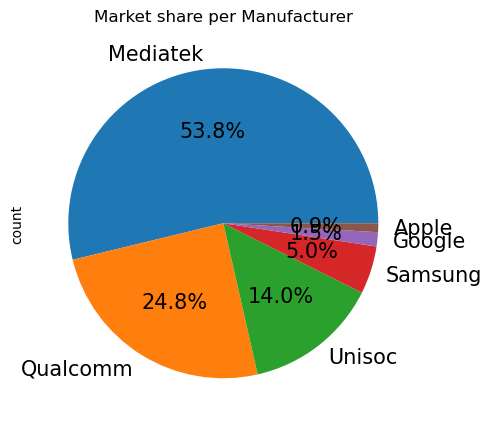

In [258]:
df['Manufacturer'].value_counts().plot(
    kind='pie',
    autopct = '%1.1f%%',
    figsize=(5,12),
    startangle=0,
    textprops={'fontsize':15},
    title='Market share per Manufacturer'
)

C:\Users\Roshni\AppData\Local\Temp\ipykernel_16596\2463482226.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stacked=df.groupby(['Manufacturer','PriceRange']).size().unstack()


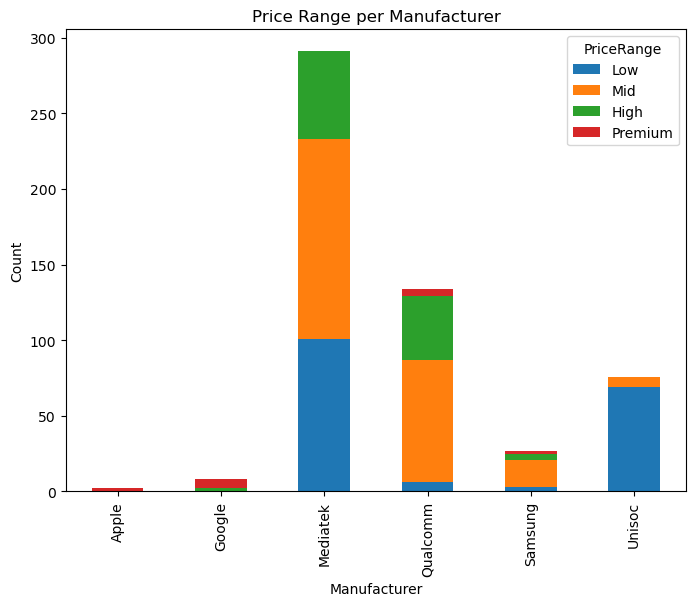

In [259]:
df['PriceRange']=pd.cut(df['Prize'],bins=[0,10000,20000,40000,80000],labels=['Low','Mid','High','Premium'])
stacked=df.groupby(['Manufacturer','PriceRange']).size().unstack()
stacked.plot(kind='bar',stacked=True,figsize=(8,6))
plt.title('Price Range per Manufacturer')
plt.ylabel('Count')
plt.show()

In [260]:
#The stacked bar chart shows that Mediatek dominates the dataset, with the highest number of devices across both low and mid‑range segments. 
#Qualcomm follows with a strong presence in mid‑range, while Unisoc contributes mainly to the low‑range category. 
#Apple and Google appear only in the premium segment, highlighting their focus on high‑end devices. 
#Samsung shows a balanced distribution across mid and high ranges, but with fewer total devices compared to Mediatek and Qualcomm

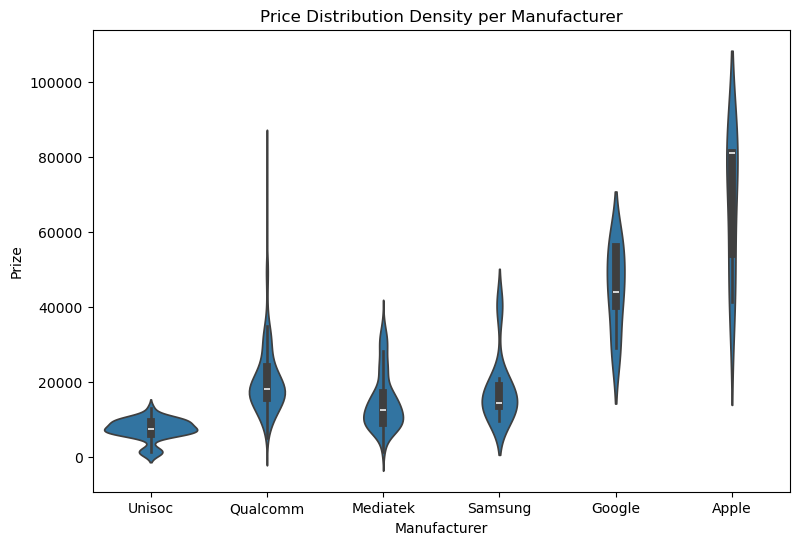

In [261]:
plt.figure(figsize=(9,6))
sns.violinplot(data=df, x='Manufacturer', y='Prize')
plt.title('Price Distribution Density per Manufacturer')
plt.show()

In [262]:
#The violin plot reveals that Apple’s prices are positively skewed, with a wide spread toward higher values, confirming its premium positioning. 
#Mediatek and Unisoc show compact distributions concentrated in the lower ranges, indicating budget‑friendly devices. 
#Qualcomm and Samsung display moderate spreads, suggesting they serve both mid and high segments. 
#The density curves highlight that most devices cluster tightly around specific price bands, while outliers extend the tails, reflecting skewness and kurtosis in the distribution.

In [263]:
df.dtypes

Unnamed: 0            int64
Model                object
Colour               object
Memory                int64
RAM                   int64
Battery_              int64
Rear Camera           int64
Front Camera          int64
AI Lens               int64
Mobile Height       float64
Processor_           object
Prize                 int64
Processor_clean      object
Manufacturer         object
Tier                 object
PriceRange         category
dtype: object

In [264]:
##ML modelling stage.

## Features and target
`y` is the price (`Prize`). `x` is the 7 numeric specs plus `Processor_clean`, `Manufacturer` and `Tier`.

**Left out on purpose:**
- `Unnamed: 0`: just a row number
- `PriceRange`: built from the price, so using it would leak the answer
- `Processor_`: replaced by the cleaned version
- `Model`: almost one value per phone, so the model could memorise it instead of learning from specs
- `Colour`: the names identify individual phones (for example 'Midnight' for iPhones) and do not describe the specs

In [265]:
x = df[['Memory','RAM','Battery_','Rear Camera','Front Camera','AI Lens','Mobile Height','Processor_clean','Manufacturer','Tier']]
y = df['Prize']

In [266]:
#X = the information given to the model

#y = the answer we want the model to learn

In [267]:
#X → phone specifications
#y → phone price

In [268]:
df.columns

Index(['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_',
       'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_',
       'Prize', 'Processor_clean', 'Manufacturer', 'Tier', 'PriceRange'],
      dtype='object')

In [269]:
df[['Manufacturer','Tier']].head()

,Manufacturer,Tier
0,Unisoc,low
1,Unisoc,low
2,Qualcomm,Mid
3,Mediatek,low
4,Mediatek,low


In [270]:
df['Tier'].value_counts()

Tier
low         231
other       160
Mid         133
Flagship     17
Name: count, dtype: int64

In [271]:
x.shape

(541, 10)

In [272]:
y.shape

(541,)

In [273]:
x.head()

,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_clean,Manufacturer,Tier
0,64,4,6000,13,5,1,16.76,unisoc sc9863a,Unisoc,low
1,64,4,6000,13,5,1,16.76,unisoc sc9863a,Unisoc,low
2,128,8,5000,50,16,0,16.64,qualcomm snapdragon 680,Qualcomm,Mid
3,32,2,5000,8,5,0,16.56,mediatek helio a22,Mediatek,low
4,128,8,5000,50,5,1,16.76,mediatek helio g37,Mediatek,low


In [274]:
x_train, x_test, y_train, y_test = train_test_split(
    x,y,
    test_size=0.20,
    random_state=42
)

In [275]:
x_train.shape,x_test.shape,y_train.shape,y_test

((432, 10),
 (109, 10),
 (432,),
 229     8499
 73      6299
 352    19499
 86     10999
 470    12599
 77     14499
 297     9999
 468    17999
 342    29499
 384     9790
 6       8999
 117    29999
 411    19499
 75     16499
 272    32999
 195    16999
 485     9999
 101    15999
 527    23999
 55     18999
 374     6999
 185    17999
 298     9999
 167    17999
 386    28298
 2      11999
 180     8049
 388    23999
 10      9499
 311     8069
 528    17499
 176    16999
 245     1699
 398    16499
 450    17999
 525    80999
 415    10943
 72     15999
 196    16999
 268     8999
 321    12999
 489    49999
 140    23999
 530    12999
 173     5999
 79     13999
 500    16999
 397     9499
 534     9790
 30      6599
 235    15999
 512    29418
 498     9999
 9       7999
 529     8460
 325    17999
 104    19999
 447    27999
 371    11980
 158    11999
 249    11970
 316    25999
 76      6299
 536    79999
 70      5999
 487     8999
 461    16499
 369    21499
 271     8999
 

In [276]:
#Created a preprocessing pipeline using ColumnTransformer to one-hot encode categorical features (Processor_clean, Manufacturer, and Tier) 
#while keeping the numerical features unchanged for machine-learning modelling.

In [277]:
#We'll eventually have something like:

#Linear Regression → Decision Tree → Random Forest → Extra Trees → Gradient Boosting → AdaBoost → XGBoost

## Modelling
One-hot encoding turns text categories into 0/1 columns, because models only understand numbers. Numeric columns pass through unchanged. The encoder is **fitted on the training data only** and then applied to the test data, so nothing leaks from the test set.

Seven models, each judged on the same test set with R², MAE, MSE and RMSE: Linear Regression (the baseline), Decision Tree, Random Forest, Extra Trees, Gradient Boosting, AdaBoost and XGBoost.

How to read the metrics: **R²** is the share of price variation explained (1 is perfect). **MAE** is the typical miss in rupees. **RMSE** is like MAE but punishes big misses more.

In [278]:
categorical_features = ['Processor_clean','Manufacturer','Tier']
preprocessor = ColumnTransformer(transformers = [('cat',OneHotEncoder(handle_unknown = 'ignore'),categorical_features)
                                               ],
                                 remainder = 'passthrough'
                                )

In [279]:
x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

x_train_processed.shape, x_test_processed.shape

((432, 81), (109, 81))

In [280]:
from sklearn.linear_model import LinearRegression
model_lr = LinearRegression()
model_lr.fit(x_train_processed, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [281]:
y_pred_lr = model_lr.predict(x_test_processed)
y_pred_lr[:10]

array([ 7009.83028693,  6486.31745892, 20181.48007092, 11607.40608652,
       12185.0934192 , 13740.56402479,  9626.79008473, 15985.90937651,
       26984.91642666,  8740.4696001 ])

In [282]:
#Evaluated the Linear Regression model using R², MAE, MSE, and RMSE to measure prediction accuracy and model performance.

In [283]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

r2_lr=r2_score(y_test,y_pred_lr)
mae_lr=mean_absolute_error(y_test,y_pred_lr)
mse_lr=mean_squared_error(y_test,y_pred_lr)
rmse_lr=np.sqrt(mse_lr)

In [284]:
print("R²:",r2_lr)
print("MAE:",mae_lr)
print("MSE:",mse_lr)
print("RMSE:",rmse_lr)

R²: 0.8342755464850689
MAE: 1917.152488384806
MSE: 22841435.84333358
RMSE: 4779.271476211995


In [285]:
from sklearn.tree import DecisionTreeRegressor

In [286]:
model_dt = DecisionTreeRegressor(random_state=42)

In [287]:
model_dt.fit(x_train_processed,y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [288]:
y_pred_dt=model_dt.predict(x_test_processed)
y_pred_dt[:10]

array([ 8499.  ,  6324.  , 19499.  , 11209.25, 13999.  , 13249.  ,
        9999.  , 17999.  , 30749.  ,  6999.  ])

In [289]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np


In [290]:
r2_dt=r2_score(y_test,y_pred_dt)
mae_dt=mean_absolute_error(y_test, y_pred_dt)
mse_dt=mean_squared_error(y_test,y_pred_dt)
rmse_dt=np.sqrt(mse_dt)

print("R²:",r2_dt)
print("MAE:",mae_dt)
print("MSE:",mse_dt)
print("RMSE:",rmse_dt)

R²: 0.868277021591142
MAE: 1206.4074923547403
MSE: 18155087.535996433
RMSE: 4260.878728149445


In [291]:
print("y_test:",y_test.shape)
print("y_pred_dt:",y_pred_dt.shape)
print("y_train:",y_train.shape)
print("x_train_processed:",x_train_processed.shape)

y_test: (109,)
y_pred_dt: (109,)
y_train: (432,)
x_train_processed: (432, 81)


In [292]:
#Decision Tree is performing better than Linear Regression

In [293]:
#The Decision Tree Regressor outperformed Linear Regression, achieving an R² of 86.83% and reducing the MAE from ₹1,917 to ₹1,206.
#Next, we'll test Random Forest Regressor, which combines many decision trees

In [294]:
from sklearn.ensemble import RandomForestRegressor
model_rf=RandomForestRegressor(random_state=42)

In [295]:
model_rf.fit(x_train_processed,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [296]:
y_pred_rf=model_rf.predict(x_test_processed)
y_pred_rf[:10]

array([ 8499.        ,  6465.68166667, 19205.18333333, 11254.34480159,
       12612.3209697 , 13266.83730159,  9978.96      , 16137.79666667,
       30099.88857143,  7563.15195238])

In [297]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
import numpy as np

r2_rf=r2_score(y_test,y_pred_rf)
mae_rf=mean_absolute_error(y_test,y_pred_rf)
mse_rf=mean_squared_error(y_test,y_pred_rf)
rmse_rf=np.sqrt(mse_rf)

In [298]:
print("R²:",r2_rf)
print("MAE:",mae_rf)
print("MSE:",mse_rf)
print("RMSE:",rmse_rf)

R²: 0.856057659768465
MAE: 1533.7995586633042
MSE: 19839255.220362984
RMSE: 4454.127885497113


In [299]:
from sklearn.ensemble import ExtraTreesRegressor
model_et=ExtraTreesRegressor(random_state=42)

In [300]:
#The Random Forest Regressor achieved an R² of 85.61% with an MAE of ₹1,534, 
#performing slightly below the Decision Tree Regressor on the test dataset.

In [301]:

model_et.fit(x_train_processed,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


In [302]:
y_pred_et=model_et.predict(x_test_processed)
y_pred_et[:10]

array([ 8499.        ,  6324.        , 19499.        , 11209.25      ,
       13810.01666667, 13249.        ,  9999.        , 17999.        ,
       30749.        ,  7798.315     ])

In [303]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
import numpy as np

In [304]:
r2_et=r2_score(y_test,y_pred_et)
mae_et=mean_absolute_error(y_test,y_pred_et)
mse_et=mean_squared_error(y_test,y_pred_et)
rmse_et=np.sqrt(mse_et)

In [305]:
print("R²:",r2_et)
print("MAE:",mae_et)
print("MSE:",mse_et)
print("RMSE:",rmse_et)

R²: 0.8232697267846252
MAE: 1164.8513914373093
MSE: 24358343.694040902
RMSE: 4935.417276587756


In [306]:
from sklearn.ensemble import GradientBoostingRegressor
model_gb=GradientBoostingRegressor(random_state=42)

In [307]:
model_gb.fit(x_train_processed,y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [308]:
y_pred_gb=model_gb.predict(x_test_processed)
y_pred_gb[:10]

array([ 8347.76933859,  7156.20665345, 19134.67286385, 10916.13427577,
       11912.53973511, 14214.93124524,  8533.74097141, 17220.26483592,
       26544.75700872,  7570.98638015])

In [309]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
import numpy as np

In [310]:
r2_gb=r2_score(y_test,y_pred_gb)
mae_gb=mean_absolute_error(y_test,y_pred_gb)
mse_gb=mean_squared_error(y_test,y_pred_gb)
rmse_gb=np.sqrt(mse_gb)

In [311]:
print("R²:",r2_gb)
print("MAE:",mae_gb)
print("MSE:",mse_gb)
print("RMSE:",rmse_gb)

R²: 0.8632040389237887
MAE: 1948.1541369173992
MSE: 18854285.546145555
RMSE: 4342.15217906346


In [312]:
#The Gradient Boosting Regressor achieved an R² of 86.32% with an RMSE of ₹4,342, 
#showing strong predictive performance and ranking closely behind the Decision Tree model.

In [313]:
from sklearn.ensemble import AdaBoostRegressor
model_ada=AdaBoostRegressor(random_state=42)

In [314]:
model_ada.fit(x_train_processed,y_train)

,estimator,None
,n_estimators,50
,learning_rate,1.0
,loss,'linear'
,random_state,42


In [315]:
y_pred_ada=model_ada.predict(x_test_processed)
y_pred_ada[:10]

array([15204.        ,  8829.76829268, 20773.60273973, 15204.        ,
       15457.28235294, 19015.57638889,  9997.        , 20341.99183673,
       29772.89915966,  8829.76829268])

In [316]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

In [317]:
r2_ada=r2_score(y_test,y_pred_ada)
mae_ada=mean_absolute_error(y_test,y_pred_ada)
mse_ada=mean_squared_error(y_test,y_pred_ada)
rmse_ada=np.sqrt(mse_ada)

In [318]:
print("R²:",r2_ada)
print("MAE:",mae_ada)
print("MSE:",mse_ada)
print("RMSE:",rmse_ada)

R²: 0.7277466828892383
MAE: 4303.833248400858
MSE: 37524074.112333335
RMSE: 6125.689684625996


In [319]:
import sys
!{sys.executable} -m pip install xgboost

In [320]:
import xgboost as xgb
print(xgb.__version__)

3.4.1


In [321]:
import xgboost as xgb
print(xgb.__version__)

3.4.1


In [322]:
from xgboost import XGBRegressor

model_xgb = XGBRegressor(random_state=42)

In [323]:
model_xgb.fit(x_train_processed,y_train)


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [324]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

In [325]:
y_pred_xgb=model_xgb.predict(x_test_processed)
y_pred_xgb[:10]

array([ 8470.901 ,  6366.4927, 19533.488 , 11261.2705, 13494.2   ,
       13347.395 ,  9986.574 , 17539.32  , 30679.79  ,  7559.792 ],
      dtype=float32)

In [326]:
r2_xgb=r2_score(y_test, y_pred_xgb)
mae_xgb=mean_absolute_error(y_test,y_pred_xgb)
mse_xgb=mean_squared_error(y_test,y_pred_xgb)
rmse_xgb=np.sqrt(mse_xgb)

In [327]:
print("R²:",r2_xgb)
print("MAE:",mae_xgb)
print("MSE:",mse_xgb)
print("RMSE:",rmse_xgb)

R²: 0.903923749923706
MAE: 1125.93115234375
MSE: 13241978.0
RMSE: 3638.9528713628597


In [328]:
df.describe()

,Unnamed: 0,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Prize
count,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000
mean,289.711645,110.550832,5.397412,4871.587800,46.110906,11.992606,0.062847,16.431201,16228.375231
std,182.359185,60.600694,1.984923,780.148862,31.260416,9.053746,0.242911,2.523553,10793.588322
min,0.000000,16.000000,2.000000,800.000000,0.000000,0.000000,0.000000,4.500000,920.000000
25%,135.000000,64.000000,4.000000,5000.000000,13.000000,5.000000,0.000000,16.510000,9290.000000
50%,273.000000,128.000000,6.000000,5000.000000,50.000000,8.000000,0.000000,16.710000,13499.000000
75%,434.000000,128.000000,8.000000,5000.000000,50.000000,16.000000,0.000000,16.940000,19280.000000
max,642.000000,256.000000,8.000000,7000.000000,200.000000,60.000000,1.000000,41.940000,80999.000000


In [329]:
print(x_train.columns.tolist())

['Memory', 'RAM', 'Battery_', 'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_clean', 'Manufacturer', 'Tier']


In [330]:
print(x_train.columns)

Index(['Memory', 'RAM', 'Battery_', 'Rear Camera', 'Front Camera', 'AI Lens',
       'Mobile Height', 'Processor_clean', 'Manufacturer', 'Tier'],
      dtype='object')


In [331]:
df['Tier'].sort_index()

0           low
1           low
2           Mid
3           low
4           low
5           low
6           low
7           low
8           low
9           low
10          Mid
11          low
12          low
13        other
14          low
15          low
16          low
17          low
18          low
19          low
20        other
21        other
22        other
23        other
24        other
25        other
26        other
27        other
28          low
29          low
30          low
31          low
32          low
33          low
34          low
35          low
36        other
37        other
38          low
39          Mid
40          low
41          Mid
42          low
43          Mid
44          Mid
45        other
46          low
47          low
48          low
49          low
50          Mid
51          Mid
52          Mid
53          low
54          Mid
55          Mid
56          Mid
57          Mid
58          Mid
59        other
60        other
61          Mid
62      

In [332]:
models={
    "Linear":model_lr,
    "Decision_Tree":model_dt,
    "Random_Forest":model_rf,
    "Extra_Trees":model_et,
    "Gradient_Booster":model_gb,
    "Ada_Boost":model_ada,
    "XGBoost":model_xgb,
}

In [333]:
from sklearn.model_selection import cross_val_score
import numpy as np

## Cross-validation
One train/test split can be lucky or unlucky. 5-fold cross-validation splits the *training* data into 5 parts: each part is hidden once while the model learns from the other 4, and the 5 scores are averaged (`MAE +/- spread`).

`neg_` appears only because scikit-learn treats a higher score as better, so errors are stored as negatives; the code flips the sign back.

How to read it: the lowest MAE with a small spread is the most reliable model.

In [334]:
for name, m in models.items():
    s=cross_val_score(m,x_train_processed,y_train, cv=5, scoring="neg_mean_absolute_error")
    print(name, "MAE:", round(-s.mean()), "+/-", round(s.std()))

Linear MAE: 2171 +/- 376
Decision_Tree MAE: 1529 +/- 351
Random_Forest MAE: 1478 +/- 144
Extra_Trees MAE: 1177 +/- 225
Gradient_Booster MAE: 1724 +/- 116
Ada_Boost MAE: 3821 +/- 245
XGBoost MAE: 958 +/- 90


In [335]:
df.columns

Index(['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_',
       'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_',
       'Prize', 'Processor_clean', 'Manufacturer', 'Tier', 'PriceRange'],
      dtype='object')

## Does a log transform of the price help?
Price is right-skewed (a few very expensive phones), so I tested training on log(price) and converting back. The idea was that it might reduce the big misses.

Result: it did **not** help XGBoost (higher MAE and RMSE), so the raw price is kept. A tested idea that did not work is still a finding.

In [336]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.base import clone
import numpy as np

In [337]:
log_models={
    "XGBoost + log": TransformedTargetRegressor(regressor=clone(model_xgb), func=np.log1p, inverse_func=np.expm1),
    "ExtraTrees + log":TransformedTargetRegressor(regressor=clone(model_et),func=np.log1p,inverse_func=np.expm1),
}
for name, m in log_models.items():
    s=cross_val_score(m,x_train_processed,y_train, cv=5,scoring="neg_mean_absolute_error")
    print(name,"MAE:",round(-s.mean()),"+/-",round(s.std()))

XGBoost + log MAE: 1178 +/- 49
ExtraTrees + log MAE: 1133 +/- 250


In [338]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.base import clone
import numpy as np

In [339]:
rmse_models={
    "XGBoost plain":clone(model_xgb),
    "XGBoost + log": TransformedTargetRegressor(regressor=clone(model_xgb), func=np.log1p, inverse_func=np.expm1),
}
for name, m in rmse_models.items():
    s=cross_val_score(m,x_train_processed, y_train, cv=5, scoring="neg_root_mean_squared_error")
    print(name, "RMSE:", round(-s.mean()),"+/-", round(s.std()))

XGBoost plain RMSE: 4514285 +/- 752537
XGBoost + log RMSE: 9295159 +/- 2389802


## Feature importance
`feature_importances_` shows how much each feature's splits reduced the model's error, scaled so the total is 1. It tells you **what the model relies on**. It does not give a rupee value per feature, and it does not prove that a feature causes the price.

Correlated features (Tier, Processor, Manufacturer) share the credit. The function below adds the one-hot pieces back together into one score per original feature.

In [340]:
import pandas as pd
feature_names=preprocessor.get_feature_names_out()
imp = pd.Series(model_xgb.feature_importances_, index=feature_names).sort_values(ascending=False)
print(imp.head(10))

cat__Tier_low                                    0.489661
cat__Processor_clean_qualcomm snapdragon 765g    0.097458
cat__Manufacturer_Google                         0.083057
cat__Manufacturer_Apple                          0.076560
remainder__Front Camera                          0.037481
cat__Processor_clean_apple a15 bionic            0.037029
cat__Tier_Flagship                               0.036810
cat__Processor_clean_google tensor g2            0.032435
cat__Processor_clean_google tensor               0.017689
cat__Tier_other                                  0.016930
dtype: float32


In [341]:
def original_name(n):
    if n.startswith("cat__"):
        rest=n[len("cat__"):]
        for c in categorical_features:
            if rest.startswith(c+"_"):
                return c
    return n.replace("remainder__", "")

grouped=imp.groupby([original_name(n) for n in imp.index]).sum().sort_values(ascending=False)
print(grouped)

Tier               0.544932
Processor_clean    0.232217
Manufacturer       0.161952
 Front Camera      0.037481
 Battery_          0.013513
 Memory            0.004137
 RAM               0.002208
 Rear Camera       0.002123
 Mobile Height     0.001190
 AI Lens           0.000247
dtype: float32


In [ ]:
import matplotlib.pyplot as plt

grouped.sort_values().plot(kind="barh", figsize=(8, 5), color="#1D9E75")
plt.title("XGBoost feature importance (one score per original feature)")
plt.xlabel("Share of the model's reliance (total = 1)")
plt.tight_layout()
plt.show()

**Reading the chart:** processor tier, processor and manufacturer carry most of the weight. The individual specs (RAM, memory, cameras) carry little *once the chipset is known*, even though each one correlates with price on its own, because specs travel together with chipset class.

The Manufacturer score comes largely from the Apple and Google columns, and there are only 5 Apple and 8 Google phones, so do not over-read it.

## Error analysis: where does the model miss?
Sorting the test errors shows that a few large misses dominate RMSE: the biggest is a premium phone priced near ₹80,000 that is predicted far lower.

Error = actual minus predicted. Positive means the model **underpredicted**; negative means it **overpredicted**.

In [342]:
import numpy as np
import pandas as pd
y_pred=model_xgb.predict(x_test_processed)
Error=(y_test.values-y_pred)
VAR=pd.DataFrame({"Actual_Price":y_test.values, "Predicted_Price":y_pred, "Error":Error, "Absolute_Error":np.abs(Error)})
VAR=VAR.sort_values(by="Absolute_Error",ascending=False)
print(VAR)

     Actual_Price  Predicted_Price         Error  Absolute_Error
63          79999     49264.699219  30734.300781    30734.300781
96          17999     30968.193359 -12969.193359    12969.193359
34          17999     30319.466797 -12320.466797    12320.466797
55          17999     25530.785156  -7531.785156     7531.785156
23          17999     13194.319336   4804.680664     4804.680664
103         16999     21104.310547  -4105.310547     4105.310547
46          16999     21104.310547  -4105.310547     4105.310547
43          12999      9482.056641   3516.943359     3516.943359
86          31989     29651.238281   2337.761719     2337.761719
66          16499     14215.714844   2283.285156     2283.285156
9            9790      7559.791992   2230.208008     2230.208008
17          15999     18182.185547  -2183.185547     2183.185547
41          49999     47977.730469   2021.269531     2021.269531
70           9999     11846.298828  -1847.298828     1847.298828
106          9999     118

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(VAR['Actual_Price'], VAR['Predicted_Price'], alpha=0.7)
top = max(VAR['Actual_Price'].max(), VAR['Predicted_Price'].max()) * 1.05
plt.plot([0, top], [0, top], 'r--', label='Perfect prediction')
plt.xlabel('Actual price')
plt.ylabel('Predicted price')
plt.title('Predicted vs actual price (test set)')
plt.legend()
plt.tight_layout()
plt.show()

## Limitations and next steps
- Only 8 of 541 phones cost more than ₹50,000, so the model cannot be trusted for flagships. The largest errors are on these.
- The same phone appears in several colours, and a random split can put one colour in training and another in test. See the validation check at the end.
- The Tier rules are hand-written, and `other` is a catch-all.
- All models use default settings, with no hyperparameter tuning yet.
- Preprocessing is fitted once on the training set before cross-validation. A Pipeline would fit it inside each fold.

**Next:** more premium phones, chipset benchmark scores and display type as features, tuning, a Pipeline, and a split that keeps each phone model together.

In [343]:
print("Repeated rows inside the test error table (same price and same prediction):", VAR.duplicated().sum())

14


In [344]:
print((y>50000).sum())

8


## Recommendations for the retailer
1. **Price from the chipset class first.** Tier and processor carry most of the price signal.
2. **Treat brand as a premium on top of the chipset,** but remember the sample is small for Apple (5) and Google (8).
3. **Do not expect large price premiums for RAM, memory or battery** once the chipset is fixed. Front camera is the strongest single spec in the model.
4. **Use the model for budget and mid-range pricing, not for flagships** (too few examples).

These describe what the model relies on. They are not proven causes of price.

## Validation check: colour variants and a stricter split
Question: is the score inflated because the same phone (in another colour) is in both the training and the test set?

**Step 1** counts exact repeats and the test phones that have an identical twin in training.

**Step 2** re-scores every model with **GroupKFold**, which keeps all rows of one phone `Model` in the same fold, and with the preprocessing inside a Pipeline so each fold is fitted only on its own training part.

How to read it: if the grouped MAE is close to the earlier cross-validation result, the earlier scores were reliable. If it is clearly higher, the earlier scores were optimistic and the grouped numbers are the honest ones.

In [ ]:
print("Exact repeated feature rows in x:", x.duplicated().sum(), "of", len(x))

train_keys = set(map(tuple, x_train.values))
twins = sum(tuple(r) in train_keys for r in x_test.values)
print("Test phones with an identical twin in training:", twins, "of", len(x_test))

In [ ]:
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.base import clone

for name, m in models.items():
    pipe = Pipeline([('prep', clone(preprocessor)), ('model', clone(m))])
    s = cross_val_score(pipe, x, y, cv=GroupKFold(n_splits=5), groups=df['Model'],
                        scoring='neg_mean_absolute_error')
    print(name, "MAE:", round(-s.mean()), "+/-", round(s.std()))